# 5. ML. Аппроксимация и преобразования функций

## 5.2 Функция потерь

In [1]:
# УНИВЕРСАЛЬНАЯ ФУНКЦИЯ ДЛЯ РАСЧЁТА MSE
import numpy as np
import matplotlib.pyplot as plt

def calculate_mse(x_points, y_points, func, func_name="f(x)", x_range=None):
    """
    Вычисляет MSE и строит график.
    
    Параметры:
    x_points - список/массив x-координат точек
    y_points - список/массив y-координат точек
    func - функция для аппроксимации
    func_name - имя функции для подписи на графике
    x_range - диапазон для построения графика (min, max)
    """
    x_points = np.array(x_points)
    y_points = np.array(y_points)
    
    # Предсказанные значения
    y_pred = func(x_points)
    
    # MSE
    squared_errors = (y_points - y_pred)**2
    mse = np.mean(squared_errors)
    
    # Вывод результатов
    print("=" * 60)
    print(f"Функция: {func_name}")
    print("=" * 60)
    print(f"{'x':>5} | {'y (факт)':>10} | {'f(x) (пред)':>12} | {'Ошибка²':>12}")
    print("-" * 50)
    for x, y, yp, err in zip(x_points, y_points, y_pred, squared_errors):
        print(f"{x:5} | {y:10.4f} | {yp:12.4f} | {err:12.4f}")
    print("-" * 50)
    print(f"MSE = {mse:.4f}\n")
    
    # Построение графика
    if x_range is None:
        x_range = (min(x_points) - 1, max(x_points) + 1)
    
    plt.figure(figsize=(10, 6))
    x_plot = np.linspace(x_range[0], x_range[1], 100)
    y_plot = func(x_plot)
    
    plt.plot(x_plot, y_plot, 'b-', linewidth=2, label=func_name)
    plt.scatter(x_points, y_points, c='red', s=100, zorder=5, label='Исходные точки')
    
    for x, y in zip(x_points, y_points):
        plt.annotate(f'({x}, {y})', xy=(x, y), xytext=(x+0.2, y+0.5))
    
    plt.xlabel('x')
    plt.ylabel('y')
    plt.title(f'Аппроксимация функцией {func_name}')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()
    
    return mse

### Практическое задание

посчитайте значение среднеквадратичной
ошибки для данных наборов точек и аппроксимирующих функций. Постройте графики
этих функций и отметьте данные точки на нем, чтобы посмотреть, как проходит через них
график аппроксимирующей функции.

**1.** (2; 12.258), (4; 17.24), (8; 30.151).

$f(x) = 3x + 5$.

Функция: f(x) = 3x + 5
    x |   y (факт) |  f(x) (пред) |      Ошибка²
--------------------------------------------------
    2 |    12.2580 |      11.0000 |       1.5826
    4 |    17.2400 |      17.0000 |       0.0576
    8 |    30.1510 |      29.0000 |       1.3248
--------------------------------------------------
MSE = 0.9883



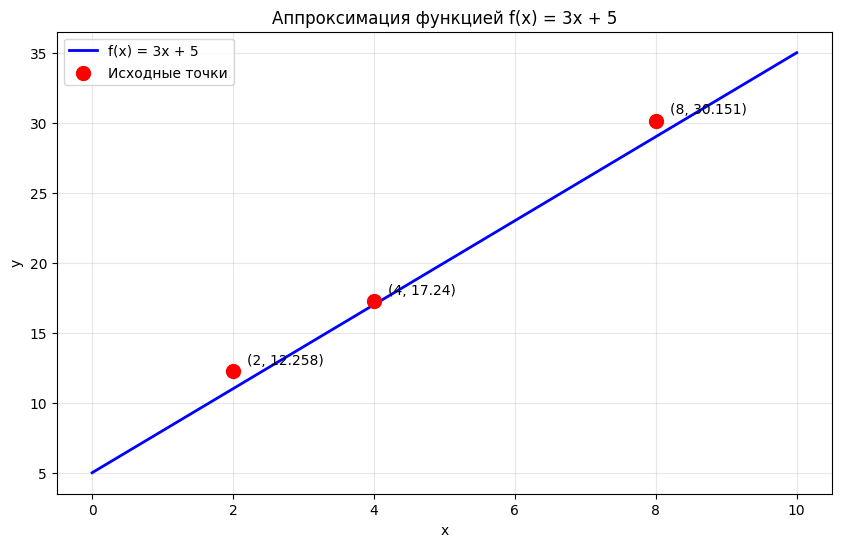

np.float64(0.9883216666666655)

In [2]:
# Задание 1 (начальный)
x1 = [2, 4, 8]
y1 = [12.258, 17.24, 30.151]
f1 = lambda x: 3*x + 5
calculate_mse(x1, y1, f1, "f(x) = 3x + 5", (0, 10))

**2.** (2; 3.688), (4; 10.791), (8; 20.705).

$f(x) = 0.25x^2 + 0.75x + 1.25.$

Функция: f(x) = 0.25x² + 0.75x + 1.25
    x |   y (факт) |  f(x) (пред) |      Ошибка²
--------------------------------------------------
    2 |     3.6880 |       3.7500 |       0.0038
    4 |    10.7910 |       8.2500 |       6.4567
    8 |    20.7050 |      23.2500 |       6.4770
--------------------------------------------------
MSE = 4.3125



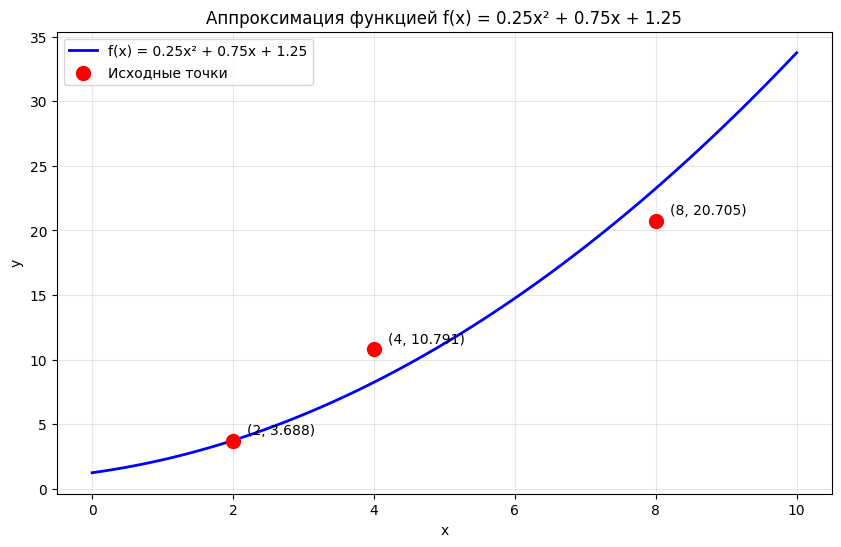

np.float64(4.31251666666667)

In [3]:
# Задание 2 (начальный)
x2 = [2, 4, 8]
y2 = [3.688, 10.791, 20.705]
f2 = lambda x: 0.25*x**2 + 0.75*x + 1.25
calculate_mse(x2, y2, f2, "f(x) = 0.25x² + 0.75x + 1.25", (0, 10))

**1.** (2; 4.872), (4; 29.707), (8; 246.971), (10; 485.727), (12; 840.658).

$f(x) = 0.5x^3 − 0.25x^2 + 0.75x + 1.25.$

Функция: f(x) = 0.5x³ - 0.25x² + 0.75x + 1.25
    x |   y (факт) |  f(x) (пред) |      Ошибка²
--------------------------------------------------
    2 |     4.8720 |       5.7500 |       0.7709
    4 |    29.7070 |      32.2500 |       6.4668
    8 |   246.9710 |     247.2500 |       0.0778
   10 |   485.7270 |     483.7500 |       3.9085
   12 |   840.6580 |     838.2500 |       5.7985
--------------------------------------------------
MSE = 3.4045



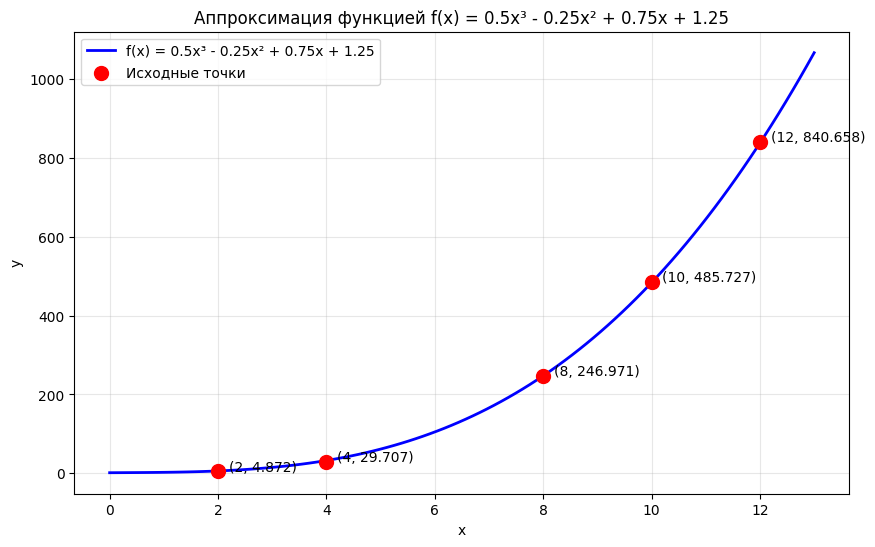

np.float64(3.404513399999994)

In [4]:
# Задание 3 (средний)
x3 = [2, 4, 8, 10, 12]
y3 = [4.872, 29.707, 246.971, 485.727, 840.658]
f3 = lambda x: 0.5*x**3 - 0.25*x**2 + 0.75*x + 1.25
calculate_mse(x3, y3, f3, "f(x) = 0.5x³ - 0.25x² + 0.75x + 1.25", (0, 13))

## 5.3 Преобразования функций. Сдвиги вправо и влево

In [5]:
from sympy import *
from sympy.plotting import plot
import numpy as np
import matplotlib.pyplot as plt
init_printing(use_unicode=False, wrap_line=False, no_global=True)

In [6]:
def print_points_ands_function(sympy_function):
    def function(x_): return float(sympy_function.subs(x, x_))

    points_X = np.array([-3, -2, -1, 1, 2, 3])
    points_Y = np.array([15.0, 8.0, 13.0, 10.0, 15.0, 30.0])
    plt.xlim(-25, 7.5)
    plt.ylim(-1, 40)

    plt.scatter(points_X, points_Y, c='r')
    x_range = np.linspace(plt.xlim()[0], plt.xlim()[1], num=100)
    function_Y = [function(x_) for x_ in x_range]
    plt.plot(x_range, function_Y, 'b')
    plt.show()

    MSE = sum([(points_Y[i] - function(points_X[i]))**2 for i in range(len(points_Y))]) / len(points_Y)
    print(f'MSE = {MSE}')

In [7]:
x = Symbol('x')
f = x ** 2 + 32 * x + 265
f

In [8]:
f = x**2
f

In [9]:
f.subs(x, -x)

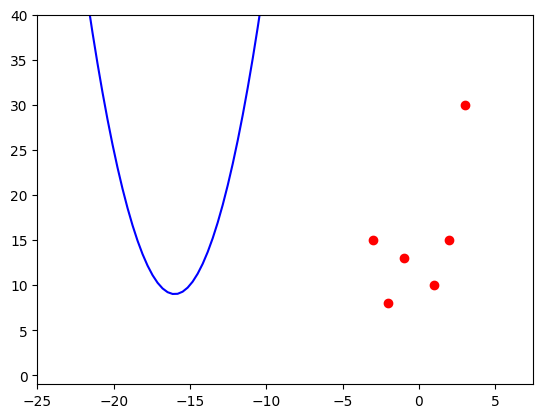

MSE = 68981.16666666667


In [10]:
f = x ** 2 + 32 * x + 265
print_points_ands_function(f)

In [11]:
f_new = f.subs(x, x - 20)
f_new

In [12]:
f_new = expand(f_new)
f_new

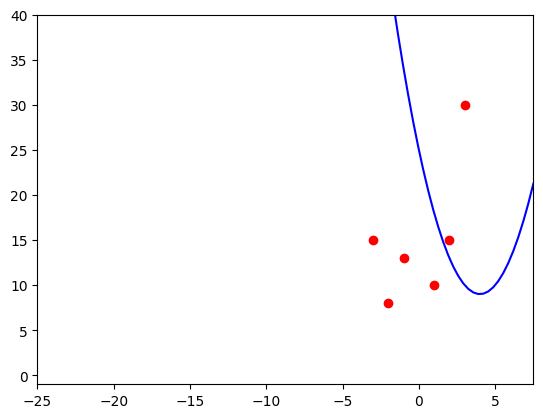

MSE = 687.8333333333334


In [13]:
print_points_ands_function(f_new)

In [14]:
f_new2 = expand(f_new.subs(x, x + 5))
f_new2

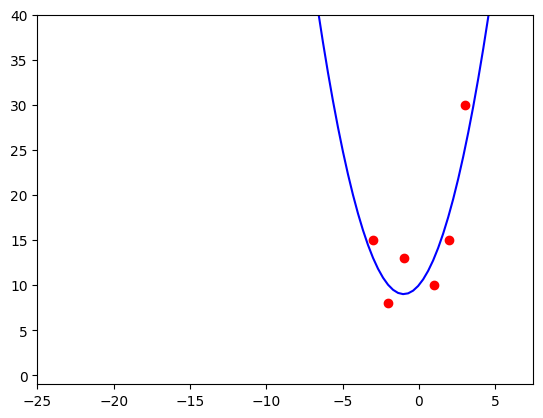

MSE = 11.166666666666666


In [15]:
print_points_ands_function(f_new2)

### 1.
### Получите значение MSE меньшее 110.

In [16]:
import matplotlib.pyplot as plt
import numpy as np

def print_points_ands_function1(sympy_function):
    def function(x_): return float(sympy_function.subs(x, x_))

    points_X = np.array([-3, -2, -1, 1, 2, 3])
    points_Y = np.array([60, 30, 19, -16, -37, -23])
    plt.xlim(-15, 15)
    plt.ylim(-40, 80)

    plt.scatter(points_X, points_Y, c='r')
    x_range = np.linspace(plt.xlim()[0], plt.xlim()[1], num=100)
    function_Y = [function(x_) for x_ in x_range]
    plt.plot(x_range, function_Y, 'b')
    plt.show()

    MSE = sum([(points_Y[i] - function(points_X[i]))**2 for i in range(len(points_Y))]) / len(points_Y)
    print(f'MSE = {MSE}')

In [17]:
x = Symbol('x')
f1 = - 14 * x - 100
f1

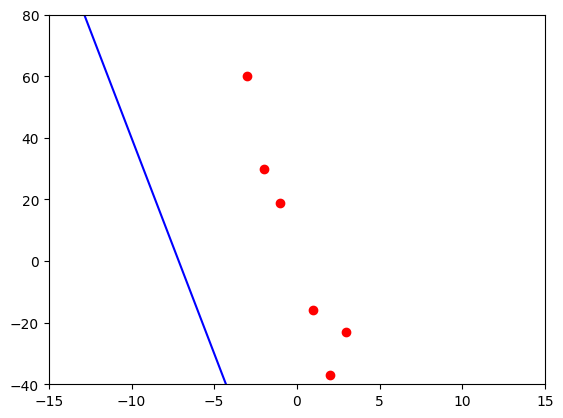

MSE = 11233.166666666666


In [18]:
print_points_ands_function1(f1)

Решение

In [19]:
f1_new = expand(f1.subs(x, x-7.54))
f1_new

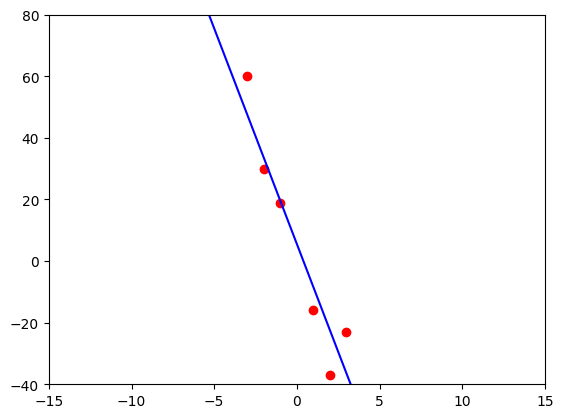

MSE = 102.92026666666668


In [20]:
print_points_ands_function1(f1_new)

### 2.
### Получите значение MSE меньшее 150.

In [21]:
def print_points_ands_function2(sympy_function):
    def function(x_): return float(sympy_function.subs(x, x_))

    points_X = np.array([-3, -2, -1, 1, 2, 3])
    points_Y = np.array([-55, -40, 7, 5, 38, 53])
    plt.xlim(-5, 25)
    plt.ylim(-70, 70)

    plt.scatter(points_X, points_Y, c='r')
    x_range = np.linspace(plt.xlim()[0], plt.xlim()[1], num=100)
    function_Y = [function(x_) for x_ in x_range]
    plt.plot(x_range, function_Y, 'b')
    plt.show()

    MSE = sum([(points_Y[i] - function(points_X[i]))**2 for i in range(len(points_Y))]) / len(points_Y)
    print(f'MSE = {MSE}')

In [22]:
f2 = 2 * x**3 - 121 * x**2 + 2443 * x - 16455
f2

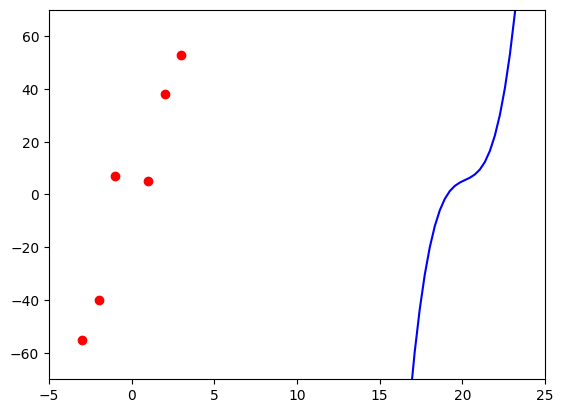

MSE = 317653781.0


In [23]:
print_points_ands_function2(f2)

Решение

In [24]:
f2_new = expand(f2.subs(x, x+20))
f2_new

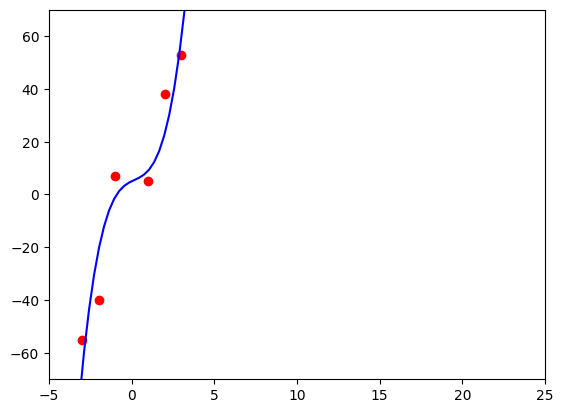

MSE = 141.0


In [25]:
print_points_ands_function2(f2_new)

## 5.4 Преобразования функций. Растяжения и сжатия

In [26]:
from sympy import *
from sympy.plotting import plot
import numpy as np
import matplotlib.pyplot as plt
init_printing(use_unicode=False, wrap_line=False, no_global=True)

In [27]:
x = Symbol('x')
f = x**2
f

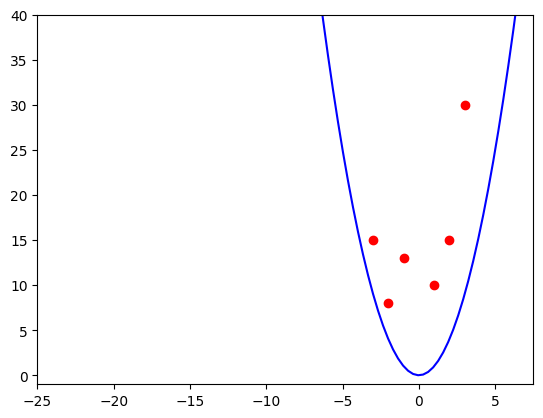

MSE = 139.83333333333334


In [28]:
print_points_ands_function(f)

In [29]:
f = x**2 / 2
f

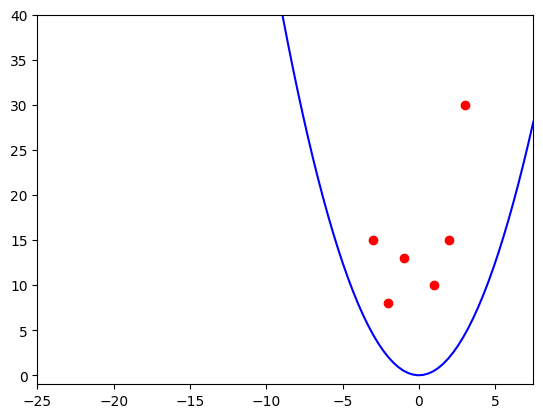

MSE = 202.0


In [30]:
print_points_ands_function(f)

In [31]:
from sympy import *
from sympy.plotting import plot
init_printing(use_unicode=False, wrap_line=False, no_global=True)

In [32]:
import matplotlib.pyplot as plt
import numpy as np

def print_points_ands_function1(sympy_function):
    def function(x_): return float(sympy_function.subs(x, x_))

    points_X = np.array([-5, -4, -3, -2, -1, 1, 2, 3, 4, 5])
    points_Y = np.array([23, 19, 5, 7, 3, 2, 9, 19, 8, 22])
    plt.xlim(-15, 15)
    plt.ylim(-5, 40)

    plt.scatter(points_X, points_Y, c='r')
    x_range = np.linspace(plt.xlim()[0], plt.xlim()[1], num=100)
    function_Y = [function(x_) for x_ in x_range]
    plt.plot(x_range, function_Y, 'b')
    plt.show()

    MSE = sum([(points_Y[i] - function(points_X[i]))**2 for i in range(len(points_Y))]) / len(points_Y)
    print(f'MSE = {MSE}')

In [33]:
x = Symbol('x')
f = x**2 / 3
f

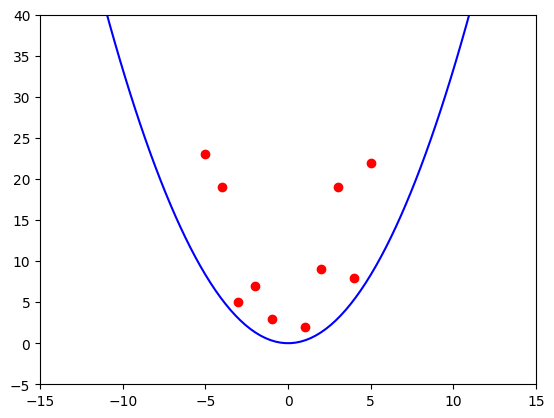

MSE = 95.65555555555554


In [34]:
print_points_ands_function1(f)

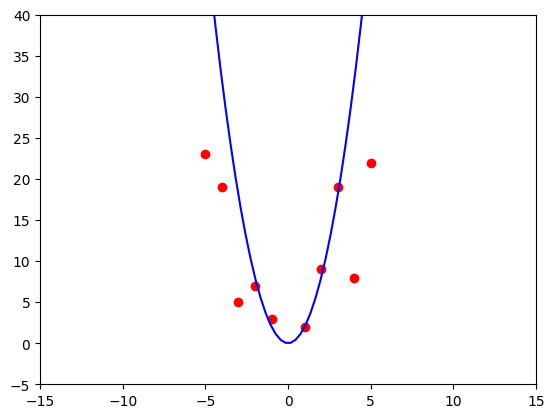

MSE = 243.1


In [35]:
f_new = 6 * f
print_points_ands_function1(f_new)

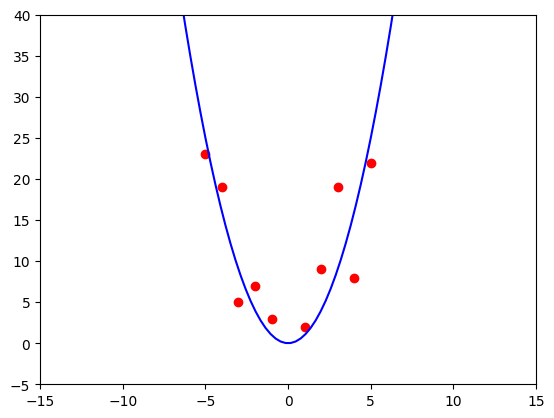

MSE = 24.1


In [36]:
f_new2 = f_new / 2
print_points_ands_function1(f_new2)

### 1.
#### Получите значение MSE меньшее 50.

In [37]:
def print_points_ands_function1(sympy_function):
    def function(x_): return float(sympy_function.subs(x, x_))

    points_X = np.array([-2, -1, 0, 1, 2, 3, 3.5, 4, 4.5, 5])
    points_Y = np.array([-15, -1, 4, -9, -2, -5, -8, 4, 13, 21])
    plt.xlim(-3, 6)
    plt.ylim(-20, 20)

    plt.scatter(points_X, points_Y, c='r')
    x_range = np.linspace(plt.xlim()[0], plt.xlim()[1], num=100)
    function_Y = [function(x_) for x_ in x_range]
    plt.plot(x_range, function_Y, 'b')
    plt.show()

    MSE = sum([(points_Y[i] - function(points_X[i]))**2 for i in range(len(points_Y))]) / len(points_Y)
    print(f'MSE = {MSE}')

In [38]:
f1 = 3.375 * x ** 3 - 9 * x**2
f1

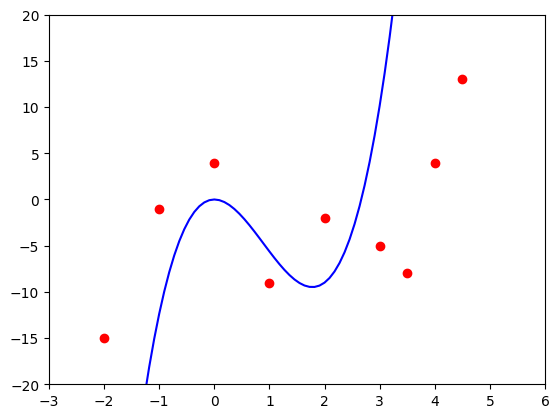

MSE = 5270.741845703125


In [39]:
print_points_ands_function1(f1)

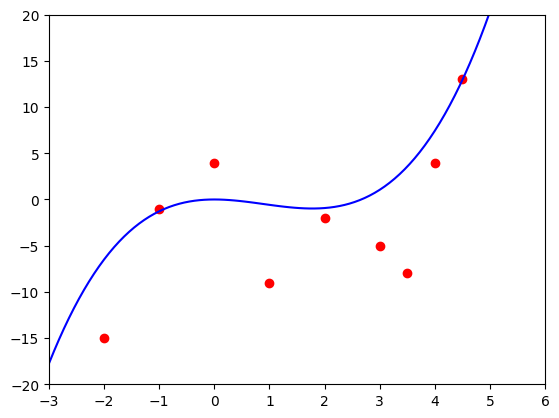

MSE = 34.26514011269131


In [40]:
f1_new = f1 / 9.7
print_points_ands_function1(f1_new)

### 2.
#### Получите значение MSE меньшее 150.

In [41]:
def print_points_ands_function2(sympy_function):
    def function(x_): return float(sympy_function.subs(x, x_))

    points_X = np.array([-3, -2, -1, 1, 2, 3])
    points_Y = np.array([-55, -40, 7, 5, 38, 53])
    plt.xlim(-10, 10)
    plt.ylim(-70, 70)

    plt.scatter(points_X, points_Y, c='r')
    x_range = np.linspace(plt.xlim()[0], plt.xlim()[1], num=100)
    function_Y = [function(x_) for x_ in x_range]
    plt.plot(x_range, function_Y, 'b')
    plt.show()

    MSE = sum([(points_Y[i] - function(points_X[i]))**2 for i in range(len(points_Y))]) / len(points_Y)
    print(f'MSE = {MSE}')

In [42]:
f2 = 0.074 * x**3 - 0.11 * x**2 + x + 5
f2

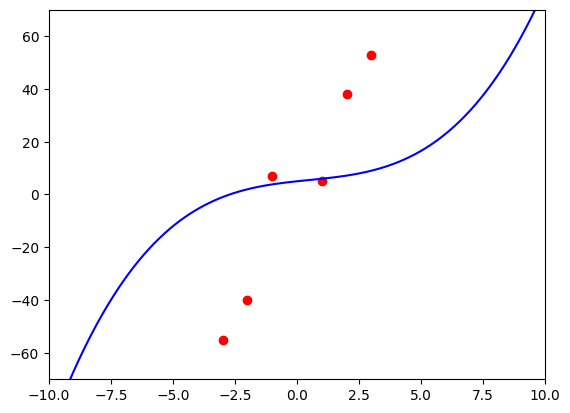

MSE = 1262.7619146666668


In [43]:
print_points_ands_function2(f2)

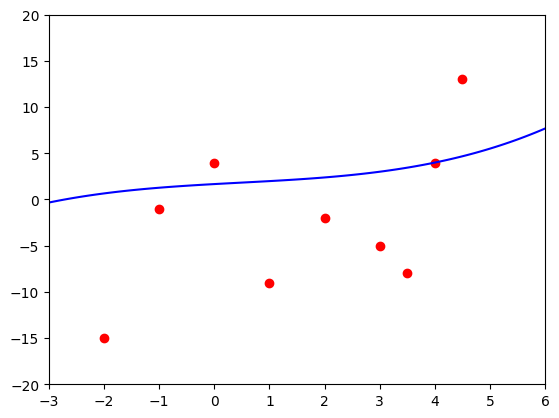

MSE = 90.02357172916666


In [44]:
f2_new = f2 / 3
print_points_ands_function1(f2_new)

## 5.5 ML как решение задачи аппроксимации

## 5.6 Итоги пройденных тем

Блок 1.

С помощью symPy найдите полиномы, описывающие данные наборы точек. Затем проведите полное исследование каждого полученного полинома: проверьте четность/нечетность, найдите нули, промежутки знакопостоянства. Постройте их графики. С помощью изменения промежутка для х добейтесь того, чтобы все нули были отображены на графике функции.


а)  $(−4;−4268),(−3;−1227),(−1;−17),(1;17),(3;1227),(4;4268)$ 

б) $(−4;−16729),(−3;−3999),(−1;5),(1;1),(3;4005),(4;16735)$

In [45]:
from sympy import *

# (−4;−4268),(−3;−1227),(−1;−17),(1;17),(3;1227),(4;4268)
# Определим символьные переменные и запишем точки в отдельные переменные, чтобы не запутаться:
a5, a4, a3, a2, a1, a0 = symbols('a5, a4, a3, a2, a1, a0')
x1, y1 = -4, -4268 
x2, y2 = -3, -1227
x3, y3 = -1, -17
x4, y4 = 1, 17
x5, y5 = 3, 1227
x6, y6 = 4, 4268

# Запишем систему и найдём коэффициенты:
eq1_lp = x1**5*a5 + x1**4*a4 + x1**3*a3 + x1**2*a2 + x1*a1 + a0 - y1 
eq2_lp = x2**5*a5 + x2**4*a4 + x2**3*a3 + x2**2*a2 + x2*a1 + a0 - y2  
eq3_lp = x3**5*a5 + x3**4*a4 + x3**3*a3 + x3**2*a2 + x3*a1 + a0 - y3 
eq4_lp = x4**5*a5 + x4**4*a4 + x4**3*a3 + x4**2*a2 + x4*a1 + a0 - y4 
eq5_lp = x5**5*a5 + x5**4*a4 + x5**3*a3 + x5**2*a2 + x5*a1 + a0 - y5 
eq6_lp = x6**5*a5 + x6**4*a4 + x6**3*a3 + x6**2*a2 + x6*a1 + a0 - y6 

nonlinsolve(
    [eq1_lp, eq2_lp, eq3_lp, eq4_lp, eq5_lp, eq6_lp], 
    [a5, a4, a3, a2, a1, a0]
)

In [46]:
# Запишем полином, описывающий предложенный набор точек:
x = Symbol('x')
f = 3 * x**5 + 19 * x**3 - 5 * x
f

In [47]:
# Проверим чётность:
print(f.subs(x, -1))
print(f.subs(x, 1))
print(f.subs(x, -100))
print(f.subs(x, 100))
print('Функция является нечётной.')

-17
17
-30018999500
30018999500
Функция является нечётной.


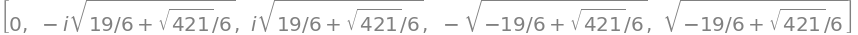

In [48]:
# Найдём нули функции:
solve(f)

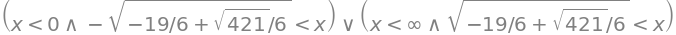

In [49]:
# Найдём промежутки возрастания и убывания функции:
solve_univariate_inequality(f > 0, x)

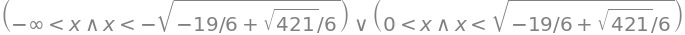

In [50]:
solve_univariate_inequality(f < 0, x)

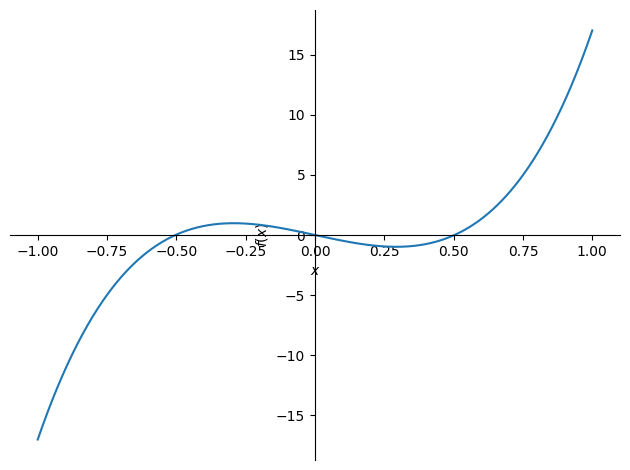

In [51]:
plot(f, (x, -1, 1))

In [52]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

def find_polynomial(points):
    """
    Находит полином по заданным точкам.
    
    points: список кортежей (x, y)
    возвращает: символьное выражение полинома
    """
    n = len(points)
    x = sp.Symbol('x')
    coeffs = sp.symbols(f'a0:{n}')
    
    # Строим полином
    f = sum(coeffs[i] * x**i for i in range(n))
    
    # Составляем и решаем систему
    equations = [f.subs(x, x_val) - y_val for x_val, y_val in points]
    solution = sp.solve(equations, coeffs)
    
    if not solution:
        raise ValueError("Система не имеет решения!")
    
    return sp.simplify(f.subs(solution))

def analyze_function(f, x, x_range=None, points=None):
    """
    Исследует функцию: чётность, нули, знакопостоянство.
    
    f: символьное выражение функции
    x: символьная переменная
    x_range: кортеж (x_min, x_max) для графика
    points: точки для отображения на графике
    """
    print("=" * 60)
    print(f"Функция: f(x) = {f}")
    print("=" * 60)
    
    # Чётность
    f_minus = f.subs(x, -x)
    if sp.simplify(f - f_minus) == 0:
        print("Чётность: ЧЁТНАЯ")
    elif sp.simplify(f + f_minus) == 0:
        print("Чётность: НЕЧЁТНАЯ")
    else:
        print("Чётность: НИ ЧЁТНАЯ, НИ НЕЧЁТНАЯ")
    
    # Нули (только действительные)
    all_zeros = sp.solve(f, x)
    real_zeros = [z for z in all_zeros if z.is_real]
    print(f"Нули (действительные): {real_zeros}")
    if real_zeros:
        print(f"Численно: {[float(z.evalf()) for z in real_zeros]}")
    
    # Знакопостоянство
    print("\n--- ПРОМЕЖУТКИ ЗНАКОПОСТОЯНСТВА ---")
    try:
        positive = sp.solve_univariate_inequality(f > 0, x)
        print(f"f(x) > 0: {positive}")
    except Exception as e:
        print(f"f(x) > 0: не удалось определить аналитически ({e})")
    
    try:
        negative = sp.solve_univariate_inequality(f < 0, x)
        print(f"f(x) < 0: {negative}")
    except Exception as e:
        print(f"f(x) < 0: не удалось определить аналитически ({e})")
    
    # Возрастание/убывание
    print("\n--- МОНОТОННОСТЬ ---")
    f_prime = sp.diff(f, x)
    print(f"Производная: f'(x) = {f_prime}")
    
    try:
        increasing = sp.solve_univariate_inequality(f_prime > 0, x)
        print(f"Возрастает: {increasing}")
    except:
        print("Возрастает: не удалось определить")
    
    try:
        decreasing = sp.solve_univariate_inequality(f_prime < 0, x)
        print(f"Убывает: {decreasing}")
    except:
        print("Убывает: не удалось определить")
    
    # ============================================
    # ПОСТРОЕНИЕ ГРАФИКА (исправленная версия)
    # ============================================
    print("\n--- ПОСТРОЕНИЕ ГРАФИКА ---")
    
    # Определяем диапазон для графика
    if x_range is not None:
        x_min, x_max = x_range
    else:
        # Автоматический расчёт диапазона
        x_vals_from_points = [p[0] for p in points] if points else []
        
        if real_zeros:
            x_zeros = [float(z.evalf()) for z in real_zeros]
            x_vals_from_zeros = x_zeros
        else:
            x_vals_from_zeros = []
        
        all_x = x_vals_from_points + x_vals_from_zeros
        if all_x:
            x_min = min(all_x) - 1
            x_max = max(all_x) + 1
        else:
            x_min, x_max = -5, 5
    
    print(f"Диапазон x: [{x_min:.2f}, {x_max:.2f}]")    
    
    # Создаём числовую функцию
    f_numeric = sp.lambdify(x, f, 'numpy')
    
    # Создаём массив x с достаточным количеством точек
    x_vals = np.linspace(x_min, x_max, 2000)    
    
    # Вычисляем y, обрабатывая возможные ошибки (деление на ноль и т.д.)
    y_vals = []
    for xv in x_vals:
        try:
            yv = float(f_numeric(xv))
            # Проверяем, не слишком ли большое значение
            if abs(yv) > 1e6:
                yv = np.nan
            y_vals.append(yv)
        except:
            y_vals.append(np.nan)
    
    y_vals = np.array(y_vals)
    
    # Создаём график
    plt.figure(figsize=(12, 7))
    
    # График функции
    plt.plot(x_vals, y_vals, 'b-', linewidth=2, label=f'f(x) = {f}')
    
    # Исходные точки
    if points:
        x_pts = [p[0] for p in points]
        y_pts = [p[1] for p in points]
        plt.scatter(x_pts, y_pts, c='red', s=100, zorder=5, label='Исходные точки')
        
        # Подписи точек
        for xp, yp in zip(x_pts, y_pts):
            plt.annotate(f'({xp}, {yp})', xy=(xp, yp), xytext=(xp + 0.2, yp + 0.5),
                        fontsize=8, ha='left')
    
    # Нули функции
    for zero in real_zeros:
        z = float(zero.evalf())
        if x_min <= z <= x_max:
            plt.scatter(z, 0, c='green', s=100, zorder=5, marker='o', 
                       edgecolors='darkgreen', linewidth=1.5,
                       label=f'Нуль: x={z:.3f}' if zero == real_zeros[0] else "")
            plt.annotate(f'x={z:.3f}', xy=(z, 0), xytext=(z, -0.5),
                        fontsize=9, ha='center', va='top')
    
    # Оси координат
    plt.axhline(0, color='black', linewidth=0.8)
    plt.axvline(0, color='black', linewidth=0.8)
    
    # Сетка
    plt.grid(True, linestyle='--', alpha=0.6)
    
    # Подписи
    plt.xlabel('x', fontsize=12)
    plt.ylabel('f(x)', fontsize=12)
    plt.title(f'График функции f(x) = {f}', fontsize=14)
    plt.legend(loc='best', fontsize=9)
    
    # Автоматическая настройка пределов y
    valid_y = y_vals[np.isfinite(y_vals)]
    if len(valid_y) > 0:
        y_min, y_max = np.percentile(valid_y, [1, 99])
        y_range = max(abs(y_min), abs(y_max))
        if y_range > 0 and y_range != float('inf'):
            plt.ylim(-y_range * 1.1, y_range * 1.1)
    
    plt.tight_layout()
    plt.show()
    
    return real_zeros





ПРИМЕР 1: Исходные точки
Функция: f(x) = x*(3*x**4 + 19*x**2 - 5)
Чётность: НЕЧЁТНАЯ
Нули (действительные): [0, -sqrt(-19/6 + sqrt(421)/6), sqrt(-19/6 + sqrt(421)/6)]
Численно: [0.0, -0.5030381908435964, 0.5030381908435964]

--- ПРОМЕЖУТКИ ЗНАКОПОСТОЯНСТВА ---
f(x) > 0: ((x < oo) & (sqrt(-19/6 + sqrt(421)/6) < x)) | ((x < 0) & (-sqrt(-19/6 + sqrt(421)/6) < x))
f(x) < 0: ((0 < x) & (x < sqrt(-19/6 + sqrt(421)/6))) | ((-oo < x) & (x < -sqrt(-19/6 + sqrt(421)/6)))

--- МОНОТОННОСТЬ ---
Производная: f'(x) = 3*x**4 + 19*x**2 + x*(12*x**3 + 38*x) - 5
Возрастает: ((x < oo) & (sqrt(-19/10 + 13*sqrt(21)/30) < x)) | ((-oo < x) & (x < -sqrt(-19/10 + 13*sqrt(21)/30)))
Убывает: (x < sqrt(-19/10 + 13*sqrt(21)/30)) & (-sqrt(-19/10 + 13*sqrt(21)/30) < x)

--- ПОСТРОЕНИЕ ГРАФИКА ---
Диапазон x: [-5.00, 5.00]


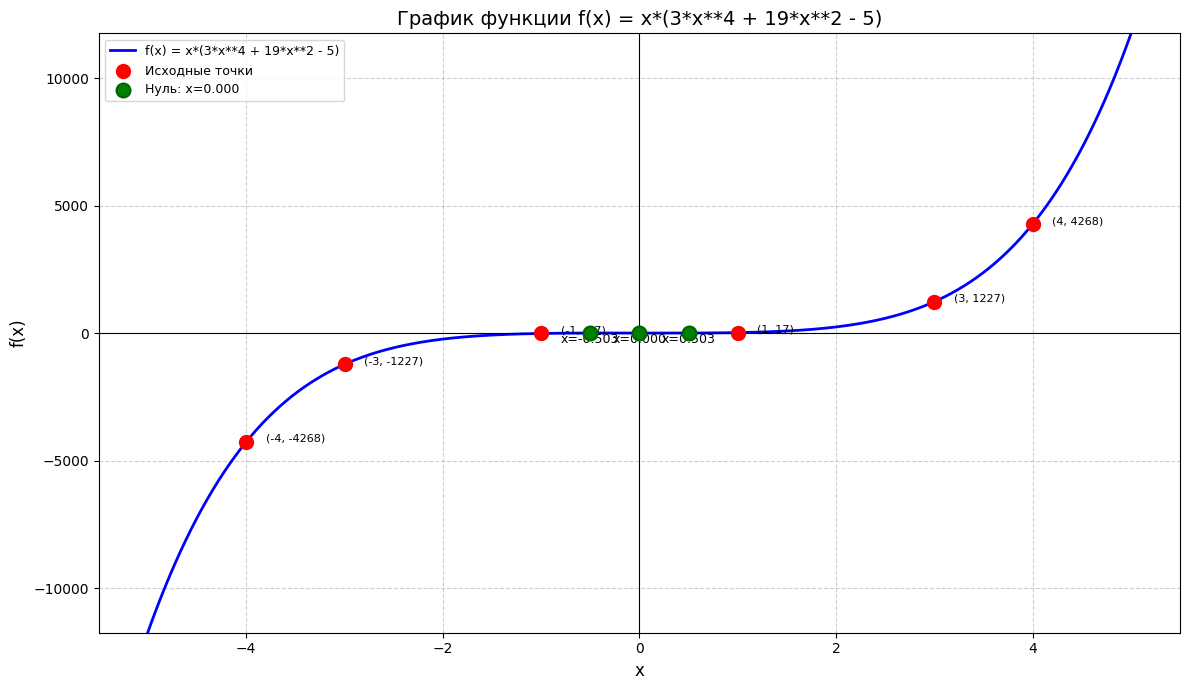

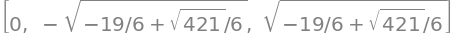

In [53]:
# ============================================
# ПРИМЕРЫ ИСПОЛЬЗОВАНИЯ
# ============================================
x = sp.Symbol('x')

# ПРИМЕР 1: Исходные точки (нечётная функция)
print("\n" * 2)
print("=" * 60)
print("ПРИМЕР 1: Исходные точки")
print("=" * 60)
points1 = [(-4, -4268), (-3, -1227), (-1, -17), (1, 17), (3, 1227), (4, 4268)]
f1 = find_polynomial(points1)
analyze_function(f1, x, points=points1)

In [ ]:
# # ПРИМЕР 2: Квадратичная функция (чётная)
# print("\n" * 2)
# print("=" * 60)
# print("ПРИМЕР 2: Квадратичная функция")
# print("=" * 60)
# points2 = [(-3, 9), (-2, 4), (-1, 1), (0, 0), (1, 1), (2, 4), (3, 9)]
# f2 = find_polynomial(points2)
# analyze_function(f2, x, points=points2)

# # ПРИМЕР 3: Линейная функция
# print("\n" * 2)
# print("=" * 60)
# print("ПРИМЕР 3: Линейная функция")
# print("=" * 60)
# points3 = [(0, 1), (1, 3), (2, 5), (3, 7)]
# f3 = find_polynomial(points3)
# analyze_function(f3, x, points=points3)

# # ПРИМЕР 4: Без точек (просто исследование функции)
# print("\n" * 2)
# print("=" * 60)
# print("ПРИМЕР 4: Исследование функции без точек")
# print("=" * 60)
# f4 = 3*x**5 + 19*x**3 - 5*x
# analyze_function(f4, x, x_range=(-5, 5))

In [54]:
# (−4;−16729),(−3;−3999),(−1;5),(1;1),(3;4005),(4;16735)
a5, a4, a3, a2, a1, a0 = symbols('a5, a4, a3, a2, a1, a0')

x1, y1 = -4, -16729 
x2, y2 = -3, -3999
x3, y3 = -1, 5
x4, y4 = 1, 1
x5, y5 = 3, 4005
x6, y6 = 4, 16735

eq1_lp = x1**5*a5 + x1**4*a4 + x1**3*a3 + x1**2*a2 + x1*a1 + a0 - y1 
eq2_lp = x2**5*a5 + x2**4*a4 + x2**3*a3 + x2**2*a2 + x2*a1 + a0 - y2  
eq3_lp = x3**5*a5 + x3**4*a4 + x3**3*a3 + x3**2*a2 + x3*a1 + a0 - y3 
eq4_lp = x4**5*a5 + x4**4*a4 + x4**3*a3 + x4**2*a2 + x4*a1 + a0 - y4 
eq5_lp = x5**5*a5 + x5**4*a4 + x5**3*a3 + x5**2*a2 + x5*a1 + a0 - y5 
eq6_lp = x6**5*a5 + x6**4*a4 + x6**3*a3 + x6**2*a2 + x6*a1 + a0 - y6 

nonlinsolve(
    [eq1_lp, eq2_lp, eq3_lp, eq4_lp, eq5_lp, eq6_lp], 
    [a5, a4, a3, a2, a1, a0]
)

In [55]:
x = Symbol('x')
f = 16* x**5 + 0 * x**4 + 7 * x**3 + 0 * x**2 - 25 * x + 3
f

In [56]:
# Проверим чётность:
print(f.subs(x, -1))
print(f.subs(x, 1))
print(f.subs(x, -100))
print(f.subs(x, 100))
print('Функция не является чётной или нечётной')

5
1
-160006997497
160006997503
Функция не является чётной или нечётной


In [57]:
# Найдём нули функции:
solve(f)

In [58]:
solve_univariate_inequality(f > 0, x)

In [59]:
solve_univariate_inequality(f < 0, x)

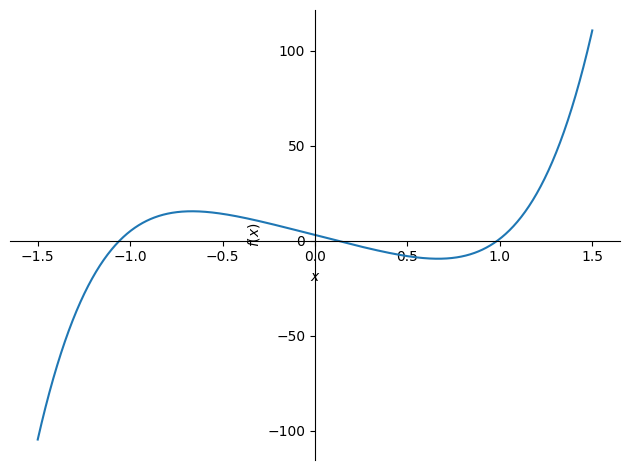

In [60]:
plot((f, (x, -1.5, 1.5)))




ПРИМЕР 1: Исходные точки
Функция: f(x) = 16*x**5 + 7*x**3 - 25*x + 3
Чётность: НИ ЧЁТНАЯ, НИ НЕЧЁТНАЯ
Нули (действительные): [CRootOf(16*x**5 + 7*x**3 - 25*x + 3, 0), CRootOf(16*x**5 + 7*x**3 - 25*x + 3, 1), CRootOf(16*x**5 + 7*x**3 - 25*x + 3, 2)]
Численно: [-1.0574892005858587, 0.12050625353328547, 0.9864075817324831]

--- ПРОМЕЖУТКИ ЗНАКОПОСТОЯНСТВА ---
f(x) > 0: ((x < oo) & (CRootOf(16*x**5 + 7*x**3 - 25*x + 3, 2) < x)) | ((x < CRootOf(16*x**5 + 7*x**3 - 25*x + 3, 1)) & (CRootOf(16*x**5 + 7*x**3 - 25*x + 3, 0) < x))
f(x) < 0: ((-oo < x) & (x < CRootOf(16*x**5 + 7*x**3 - 25*x + 3, 0))) | ((x < CRootOf(16*x**5 + 7*x**3 - 25*x + 3, 2)) & (CRootOf(16*x**5 + 7*x**3 - 25*x + 3, 1) < x))

--- МОНОТОННОСТЬ ---
Производная: f'(x) = 80*x**4 + 21*x**2 - 25
Возрастает: ((x < oo) & (sqrt(-21/160 + sqrt(8441)/160) < x)) | ((-oo < x) & (x < -sqrt(-21/160 + sqrt(8441)/160)))
Убывает: (x < sqrt(-21/160 + sqrt(8441)/160)) & (-sqrt(-21/160 + sqrt(8441)/160) < x)

--- ПОСТРОЕНИЕ ГРАФИКА ---
Диапазо

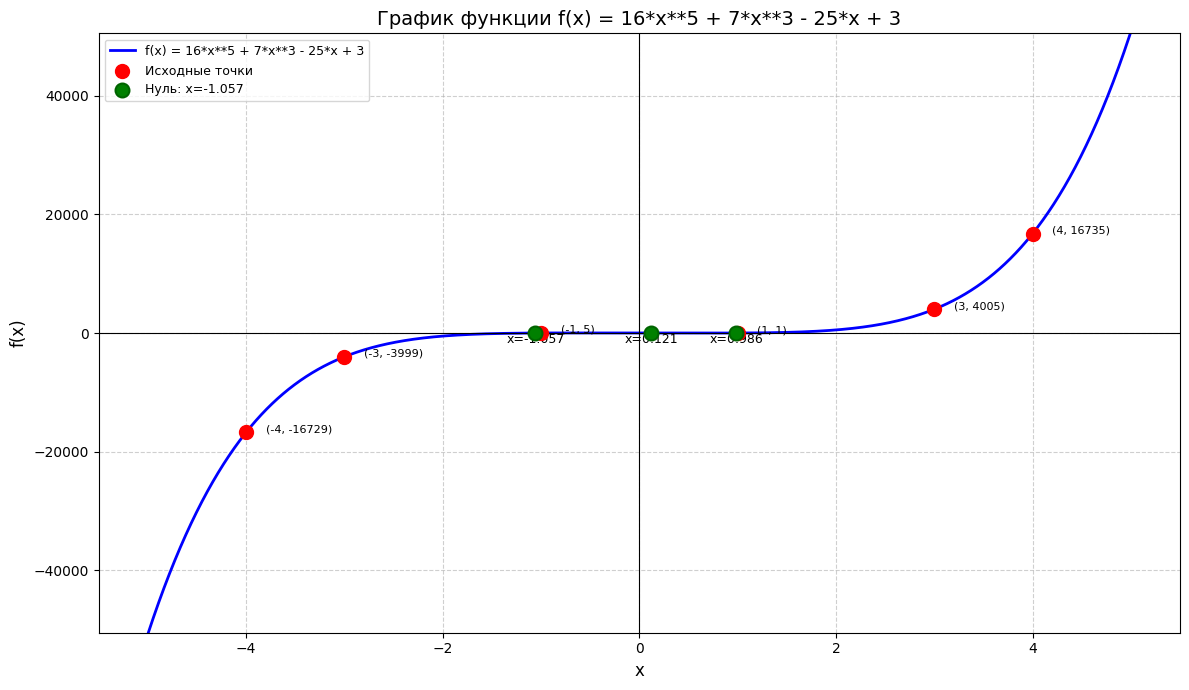

In [61]:
# ============================================
# ПРИМЕРЫ ИСПОЛЬЗОВАНИЯ
# ============================================
x = sp.Symbol('x')
# (−4;−16729),(−3;−3999),(−1;5),(1;1),(3;4005),(4;16735)
# ПРИМЕР 1: Исходные точки (нечётная функция)
print("\n" * 2)
print("=" * 60)
print("ПРИМЕР 1: Исходные точки")
print("=" * 60)
points1 = [(-4, -16729), (-3, -3999), (-1, 5), (1, 1), (3, 4005), (4, 16735)]
f1 = find_polynomial(points1)
analyze_function(f1, x, points=points1)

Блок 2.

In [62]:
from sympy import *
from sympy.plotting import plot
init_printing(use_unicode=False, wrap_line=False, no_global=True)
import matplotlib.pyplot as plt
import numpy as np

x = Symbol('x')

1.

Получите значение MSE меньшее 5.

In [66]:
def print_points_ands_function1(sympy_function):
    def function(x_): return float(sympy_function.subs(x, x_))
    
    points_X = np.array([-2, -1, 0, 1, 2, 3, 3.5, 4, 4.5, 5])
    points_Y = np.array([2, -4, 1, 8, 21, 40, 47, 65, 75, 92])
    plt.xlim(-6, 10)
    plt.ylim(-1, 100)
    
    plt.scatter(points_X, points_Y, c='r')
    x_range = np.linspace(plt.xlim()[0], plt.xlim()[1], num=100)
    function_Y = [function(x_) for x_ in x_range]
    plt.plot(x_range, function_Y, 'b')
    plt.show()
    
    MSE = sum([(points_Y[i] - function(points_X[i]))**2 for i in range(len(points_Y))]) / len(points_Y)
    print(f'MSE = {MSE}')

In [67]:
f1 = 48 * x**2 - 128 * x + 83
f1

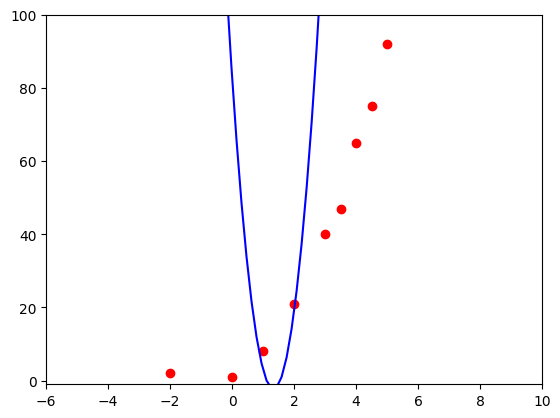

MSE = 93691.3


In [68]:
print_points_ands_function1(f1)

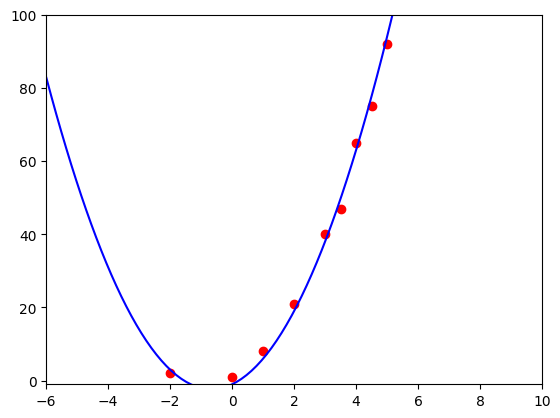

MSE = 4.4125


In [69]:
# Сместим график на шесть единиц влево:
# Растянем график вдоль оси Ox, поделив аргумент на четыре
f1_1 = f1.subs(x, (x + 6) / 4)
print_points_ands_function1(f1_1)
expand(f1_1)

MSE = 4.4125
3*x**2 + 4*x - 1


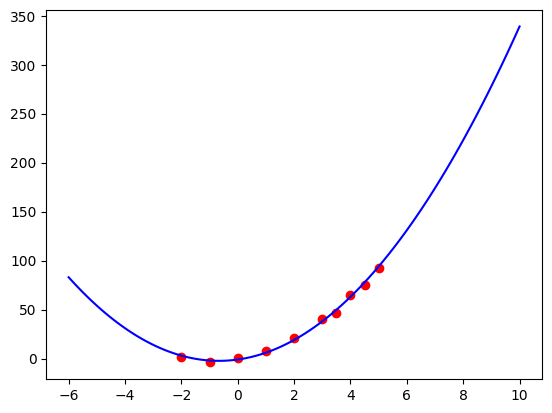

In [70]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

x = sp.Symbol('x')

# Данные
points_X = np.array([-2, -1, 0, 1, 2, 3, 3.5, 4, 4.5, 5])
points_Y = np.array([2, -4, 1, 8, 21, 40, 47, 65, 75, 92])

# Исходная функция
f1 = 48 * x**2 - 128 * x + 83

# Преобразование: сдвиг влево на 6, растяжение в 4 раза
f1_new = f1.subs(x, (x + 6) / 4)

# Расчёт MSE
f_func = sp.lambdify(x, f1_new, 'numpy')
y_pred = f_func(points_X)
MSE = np.mean((points_Y - y_pred)**2)

print(f"MSE = {MSE}")
print(expand(f1_new))

# График
plt.scatter(points_X, points_Y, c='r')
x_range = np.linspace(-6, 10, 100)
plt.plot(x_range, f_func(x_range), 'b')
plt.show()

2.

Получите значение MSE меньшее 35.

In [71]:
def print_points_ands_function2(sympy_function):
    def function(x_): return float(sympy_function.subs(x, x_))
    
    points_X = np.array([-2, -1, 0, 1, 2, 3, 3.5, 4, 4.5, 5])
    points_Y = np.array([-31, -9, 4, -1, 9, 24, 47, 92, 120, 170])
    plt.xlim(-3, 6)
    plt.ylim(-35, 200)
    
    plt.scatter(points_X, points_Y, c='r')
    x_range = np.linspace(plt.xlim()[0], plt.xlim()[1], num=100)
    function_Y = [function(x_) for x_ in x_range]
    plt.plot(x_range, function_Y, 'b')
    plt.show()
    
    MSE = sum([(points_Y[i] - function(points_X[i]))**2 for i in range(len(points_Y))]) / len(points_Y)
    print(f'MSE = {MSE}')

In [72]:
f2 = 4 * x**3 + 30 * x**2 + 74 * x + 62
f2

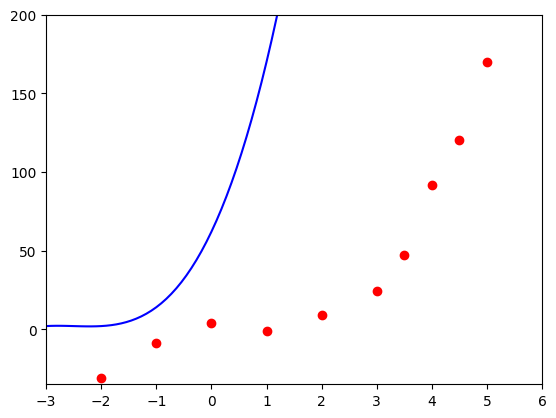

MSE = 607200.2


In [73]:
print_points_ands_function2(f2)

4*x**3 + 30*x**2 + 74*x + 62


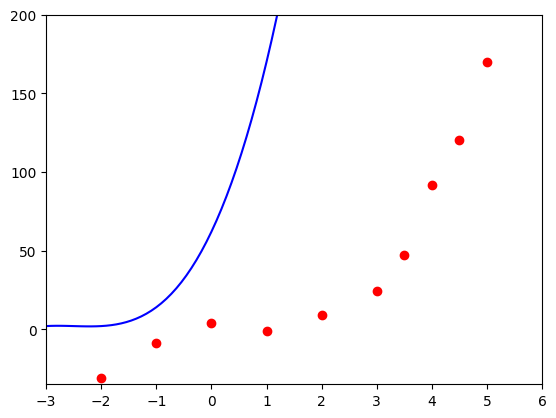

MSE = 607200.2


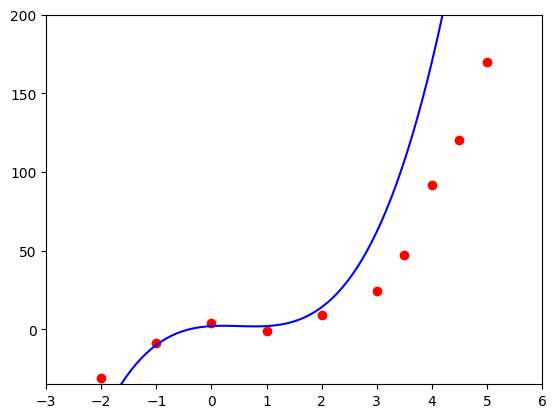

MSE = 6671.6
4*x**3 - 6*x**2 + 2*x + 2


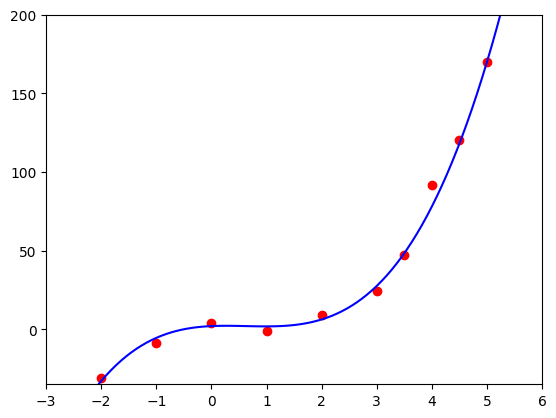

MSE = 24.89321599999999


In [74]:
def print_points_ands_function2(sympy_function):
    def function(x_): return float(sympy_function.subs(x, x_))
    
    points_X = np.array([-2, -1, 0, 1, 2, 3, 3.5, 4, 4.5, 5])
    points_Y = np.array([-31, -9, 4, -1, 9, 24, 47, 92, 120, 170])
    plt.xlim(-3, 6)
    plt.ylim(-35, 200)
    
    plt.scatter(points_X, points_Y, c='r')
    x_range = np.linspace(plt.xlim()[0], plt.xlim()[1], num=100)
    function_Y = [function(x_) for x_ in x_range]
    plt.plot(x_range, function_Y, 'b')
    plt.show()
    
    MSE = sum([(points_Y[i] - function(points_X[i]))**2 for i in range(len(points_Y))]) / len(points_Y)
    print(f'MSE = {MSE}')

# Начнём с исходной функции и будем проводить преобразования последовательно:
f2 = 4 * x**3 + 30 * x**2 + 74 * x + 62
print(f2)

print_points_ands_function2(f2)

# Сместим график на три единицы вправо:
f2_1 = f2.subs(x, x - 3)
print_points_ands_function2(f2_1)
print(expand(f2_1))

# Растянем график вдоль оси Ox:
f2_2 = f2_1.subs(x, x * 0.8)
print_points_ands_function2(f2_2)
expand(f2_2)

Исходная функция:


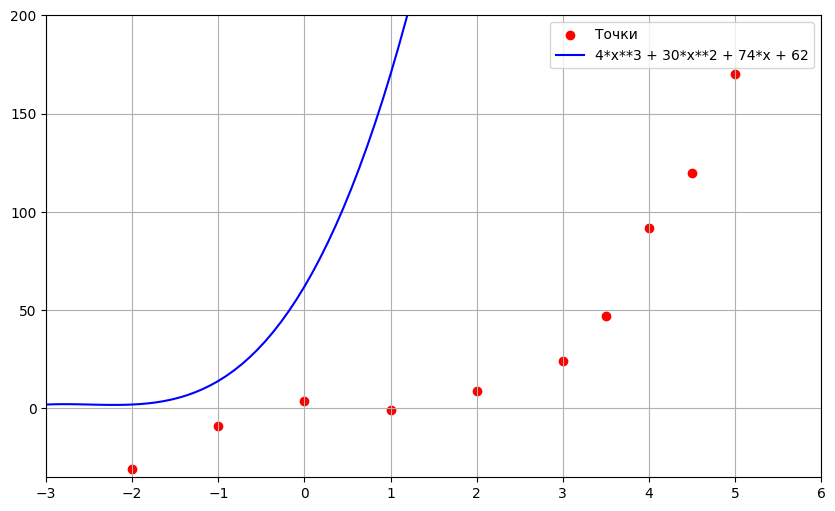

MSE = 607200.200000

После сдвига вправо на 3:


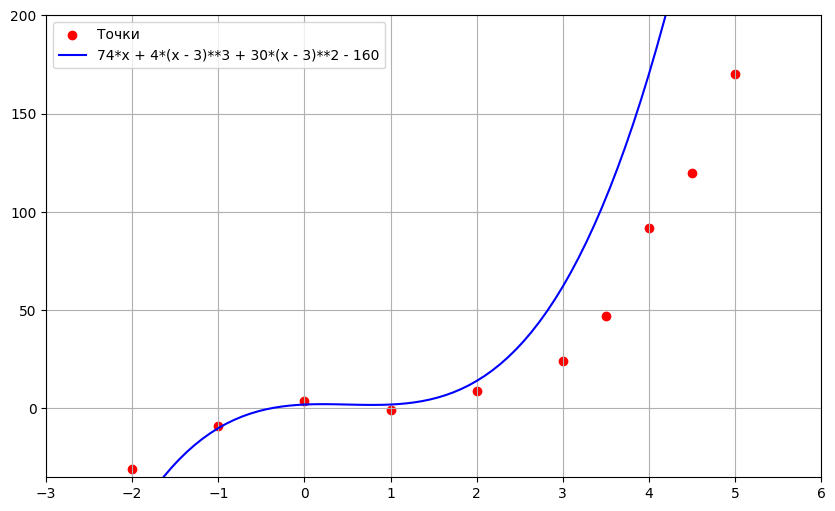

MSE = 6671.600000

После растяжения (x → 0.8·x):


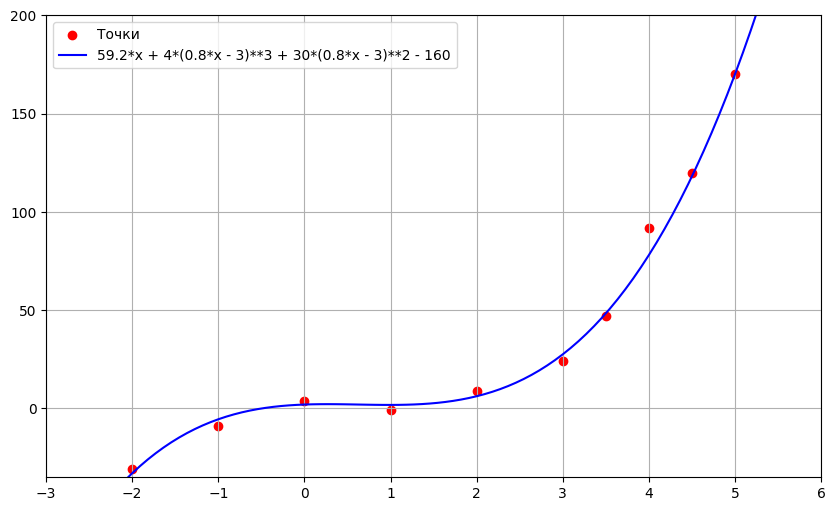

MSE = 24.893216

Итоговая функция в развёрнутом виде:
2.048*x**3 - 3.84*x**2 + 1.59999999999999*x + 2


In [75]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

x = sp.Symbol('x')

def print_points_and_function2(sympy_function):
    def function(x_): return float(sympy_function.subs(x, x_))
    
    points_X = np.array([-2, -1, 0, 1, 2, 3, 3.5, 4, 4.5, 5])
    points_Y = np.array([-31, -9, 4, -1, 9, 24, 47, 92, 120, 170])
    
    plt.figure(figsize=(10, 6))
    plt.xlim(-3, 6)
    plt.ylim(-35, 200)
    plt.scatter(points_X, points_Y, c='r', label='Точки')
    
    x_range = np.linspace(-3, 6, 100)
    function_Y = [function(x_) for x_ in x_range]
    plt.plot(x_range, function_Y, 'b', label=f'{sympy_function}')
    
    plt.grid(True)
    plt.legend()
    plt.show()
    
    y_pred = [function(x_) for x_ in points_X]
    mse = np.mean((points_Y - y_pred)**2)
    print(f'MSE = {mse:.6f}\n')

# Исходная функция
f2 = 4 * x**3 + 30 * x**2 + 74 * x + 62
print("Исходная функция:")
print_points_and_function2(f2)

# Шаг 1: сдвиг вправо на 3
f2_shift = f2.subs(x, x - 3)
print("После сдвига вправо на 3:")
print_points_and_function2(f2_shift)

# Шаг 2: растяжение (умножение аргумента на 0.8)
f2_final = f2_shift.subs(x, x * 0.8)
print("После растяжения (x → 0.8·x):")
print_points_and_function2(f2_final)

print("Итоговая функция в развёрнутом виде:")
print(sp.expand(f2_final))

3.

Получите значение MSE меньшее 3300.

In [76]:
def print_points_ands_function3(sympy_function):
    def function(x_): return float(sympy_function.subs(x, x_))
    
    points_X = np.array([-2, -1, 0, 1, 2, 3, 3.5, 4, 4.5, 5])
    points_Y = np.array([60, 25, 4, -0, -57, -195, -295, -540, -700, -760])
    plt.xlim(-10, 6)
    plt.ylim(-850, 100)
    
    plt.scatter(points_X, points_Y, c='r')
    x_range = np.linspace(plt.xlim()[0], plt.xlim()[1], num=100)
    function_Y = [function(x_) for x_ in x_range]
    plt.plot(x_range, function_Y, 'b')
    plt.show()
    
    MSE = sum([(points_Y[i] - function(points_X[i]))**2 for i in range(len(points_Y))]) / len(points_Y)
    print(f'MSE = {MSE}')

In [77]:
f3 = -36 * x**3 - 756 * x**2 - 5334 * x - 12636
f3

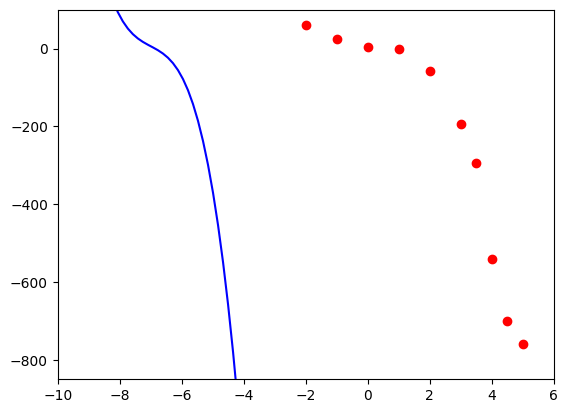

MSE = 1346344545.35


In [78]:
print_points_ands_function3(f3)

-36*x**3 - 756*x**2 - 5334*x - 12636


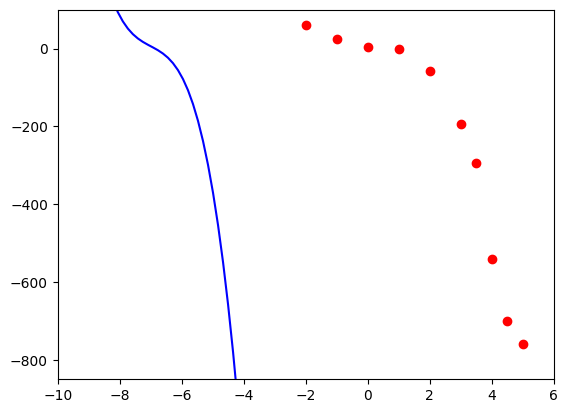

MSE = 1346344545.35


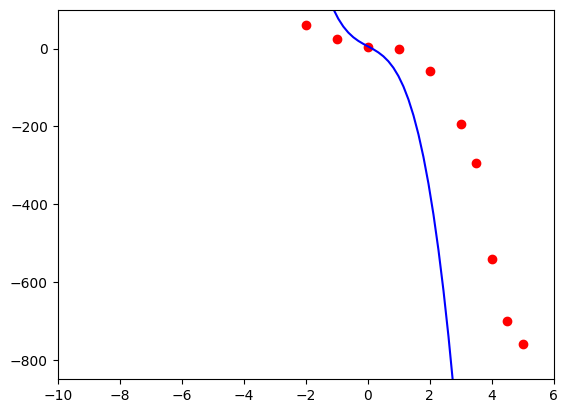

MSE = 2984213.75


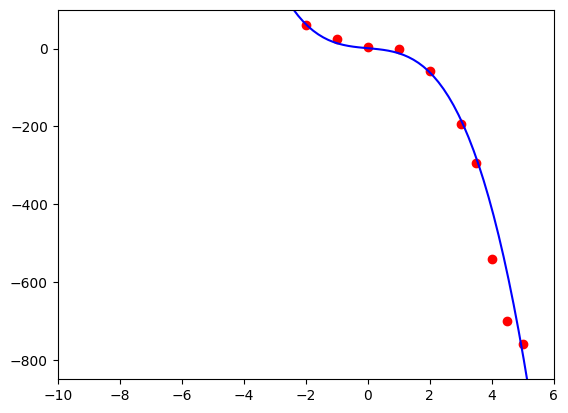

MSE = 3295.5625


In [79]:
# Начнём с исходной функции и будем выполнять преобразования последовательно:
f3 = -36 * x**3 - 756 * x**2 - 5334 * x - 12636
print(f3)
print_points_ands_function3(f3)

# Перенесём график вдоль оси Ox на семь единиц вправо:
f3_1 = f3.subs(x, x - 7)
print_points_ands_function3(f3_1)
expand(f3_1)

# Сожмём график относительно оси Oy:
f3_2 = f3_1 / 6
print_points_ands_function3(f3_2)
expand(f3_2)

4.

Получите значение MSE меньшее 25.

In [80]:
def print_points_ands_function4(sympy_function):
    def function(x_): return float(sympy_function.subs(x, x_))
    
    points_X = np.array([-2, -1, 0, 1, 2, 3, 3.5, 4, 4.5, 5])
    points_Y = np.array([-42, -37, -23, -36, -45, -80, -83, -110, -131, -155])
    plt.xlim(-4, 20)
    plt.ylim(-160, -10)
    
    plt.scatter(points_X, points_Y, c='r')
    x_range = np.linspace(plt.xlim()[0], plt.xlim()[1], num=100)
    function_Y = [function(x_) for x_ in x_range]
    plt.plot(x_range, function_Y, 'b')
    plt.show()
    
    MSE = sum([(points_Y[i] - function(points_X[i]))**2 for i in range(len(points_Y))]) / len(points_Y)
    print(f'MSE = {MSE}')

In [81]:
f4 = - 5 / 4 * x**2 + 25 * x - 152
f4

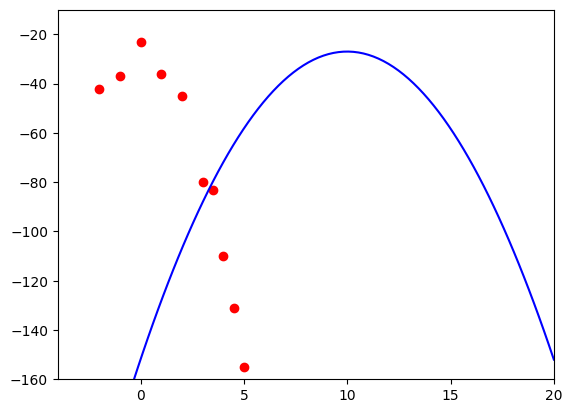

MSE = 9143.51953125


In [82]:
print_points_ands_function4(f4)

-1.25*x**2 + 25*x - 152


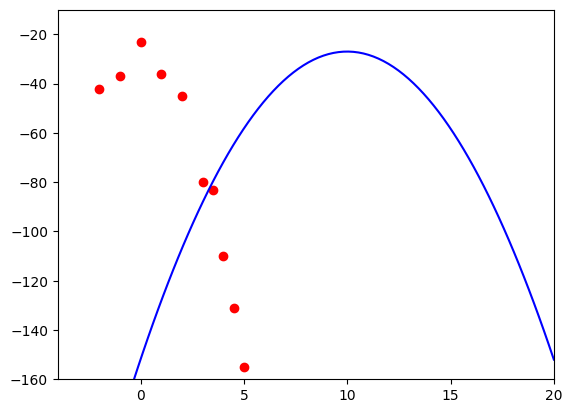

MSE = 9143.51953125


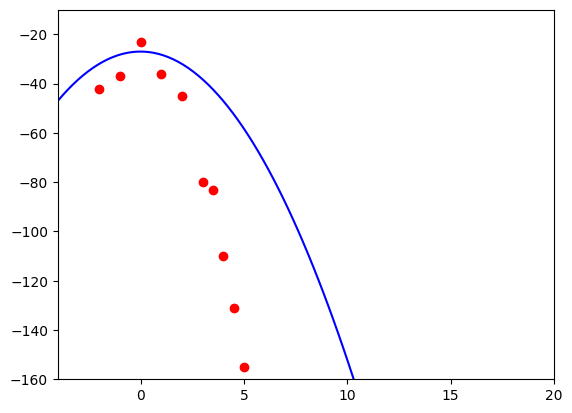

MSE = 2334.14453125


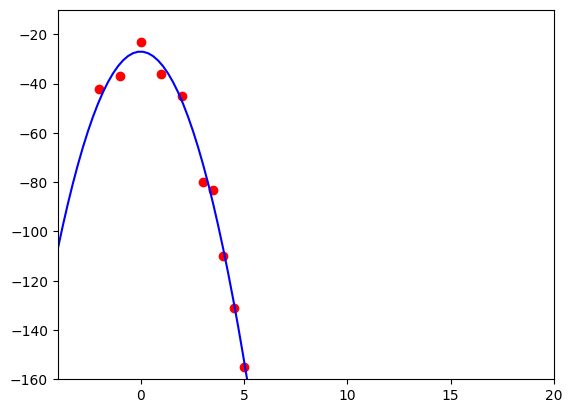

MSE = 20.3125


In [83]:
# Начнём с исходной функции и будем выполнять преобразования последовательно:
f4 = - 5 / 4 * x**2 + 25 * x - 152
print(f4)
print_points_ands_function4(f4)


# Перенесём график вдоль оси Ox на десять единиц вправо:
f4_1 = f4.subs(x, x + 10)
print_points_ands_function4(f4_1)
expand(f4_1)

# Сожмём график относительно оси Oy:
f4_2 = f4_1.subs(x, x * 2)
print_points_ands_function4(f4_2)
expand(f4_2)


## Самостоятельная работа:  Исследование полиномов Преобразование графиков

### Блок 1. Исследование полиномов

С помощью SymPy найдите полиномы, описывающие наборы точек.

Затем проведите полное исследование каждого полученного полинома:

- проверьте чётность / нечётность;

- найдите нули;

- найдите промежутки знакопостоянства;

- постройте их графики.

Изменяя промежуток для x, добейтесь того, чтобы все нули отображались на графике функции

1.
(−4,−4268), (−3,−1227), (−1,−17), (1,17), (3,1227), (4,4268)

In [84]:
import sympy as sp
from sympy.plotting import plot

x = sp.Symbol('x')

# Точки
points = [(-4, -4268), (-3, -1227), (-1, -17), (1, 17), (3, 1227), (4, 4268)]

# Определяем коэффициенты
a5, a4, a3, a2, a1, a0 = sp.symbols('a5 a4 a3 a2 a1 a0')

# Составляем уравнения
equations = []
for x_val, y_val in points:
    eq = a5*x_val**5 + a4*x_val**4 + a3*x_val**3 + a2*x_val**2 + a1*x_val + a0 - y_val
    equations.append(eq)

# Решаем систему
solution = sp.solve(equations, (a5, a4, a3, a2, a1, a0))
f = (a5*x**5 + a4*x**4 + a3*x**3 + a2*x**2 + a1*x + a0).subs(solution)
f = sp.simplify(f)

print(f"Полином: ")
f

Полином: 


In [85]:
# Чётность
f_minus = f.subs(x, -x)
if sp.simplify(f - f_minus) == 0:
    print("Чётная")
elif sp.simplify(f + f_minus) == 0:
    print("Нечётная")
else:
    print("Ни чётная, ни нечётная")

Нечётная


Нули: 


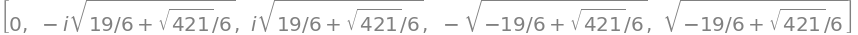

In [86]:
# Нули
zeros = sp.solve(f, x)
print(f"Нули: ")
zeros

In [87]:
import sympy as sp

x = sp.Symbol('x')
f = 3*x**5 + 19*x**3 - 5*x

zeros = sp.solve(f, x)

print("Нули функции:")
for z in zeros:
    if z.is_real:
        print(f"  x = {z} ≈ {float(z.evalf()):.6f}")
    else:
        print(f"  x = {z} (комплексный)")

Нули функции:
  x = 0 ≈ 0.000000
  x = -I*sqrt(19/6 + sqrt(421)/6) (комплексный)
  x = I*sqrt(19/6 + sqrt(421)/6) (комплексный)
  x = -sqrt(-19/6 + sqrt(421)/6) ≈ -0.503038
  x = sqrt(-19/6 + sqrt(421)/6) ≈ 0.503038


In [88]:
import sympy as sp

x = sp.Symbol('x')
f = 3*x**5 + 19*x**3 - 5*x

zeros = sp.solve(f, x)

print("=" * 50)
print("ИССЛЕДОВАНИЕ ФУНКЦИИ")
print("=" * 50)
print(f"f(x) = {f}")

print("\n1. ЧЁТНОСТЬ:")
if sp.simplify(f - f.subs(x, -x)) == 0:
    print("   Чётная")
elif sp.simplify(f + f.subs(x, -x)) == 0:
    print("   Нечётная")
else:
    print("   Ни чётная, ни нечётная")

print("\n2. НУЛИ ФУНКЦИИ:")
real_zeros = [z for z in zeros if z.is_real]
simplified_zeros = []
for z in real_zeros:
    if z == 0:
        simplified_zeros.append(0)
    else:
        simplified_zeros.append(sp.sqrt(sp.simplify(z**2)))

for z in simplified_zeros:
    print(f"   x = {z}")

print("\n3. ПРОМЕЖУТКИ ЗНАКОПОСТОЯНСТВА:")
print(f"   f(x) > 0: {sp.solve_univariate_inequality(f > 0, x)}")
print(f"   f(x) < 0: {sp.solve_univariate_inequality(f < 0, x)}")

ИССЛЕДОВАНИЕ ФУНКЦИИ
f(x) = 3*x**5 + 19*x**3 - 5*x

1. ЧЁТНОСТЬ:
   Нечётная

2. НУЛИ ФУНКЦИИ:
   x = 0
   x = sqrt(-19/6 + sqrt(421)/6)
   x = sqrt(-19/6 + sqrt(421)/6)

3. ПРОМЕЖУТКИ ЗНАКОПОСТОЯНСТВА:
   f(x) > 0: ((x < oo) & (sqrt(-19/6 + sqrt(421)/6) < x)) | ((x < 0) & (-sqrt(-19/6 + sqrt(421)/6) < x))
   f(x) < 0: ((0 < x) & (x < sqrt(-19/6 + sqrt(421)/6))) | ((-oo < x) & (x < -sqrt(-19/6 + sqrt(421)/6)))


f(x) > 0: 


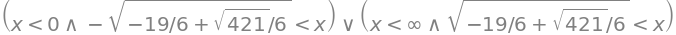

In [89]:
# Знакопостоянство
print(f"f(x) > 0: ")
sp.solve_univariate_inequality(f > 0, x)


f(x) < 0: 


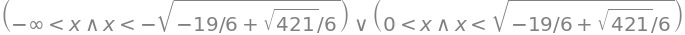

In [90]:
print(f"f(x) < 0: ")
sp.solve_univariate_inequality(f < 0, x)

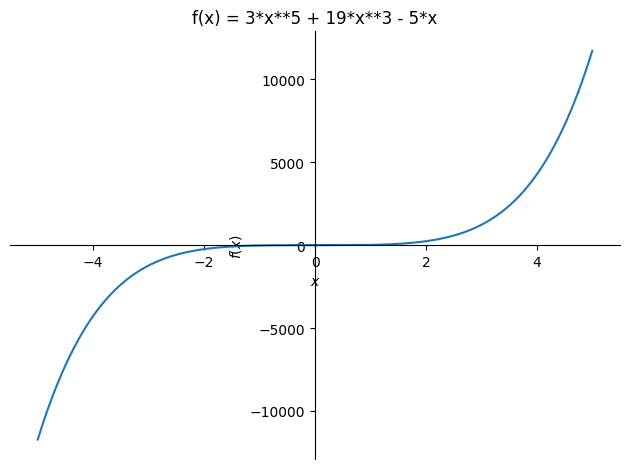

In [91]:
# График
plot(f, (x, -5, 5), title=f'f(x) = {f}');

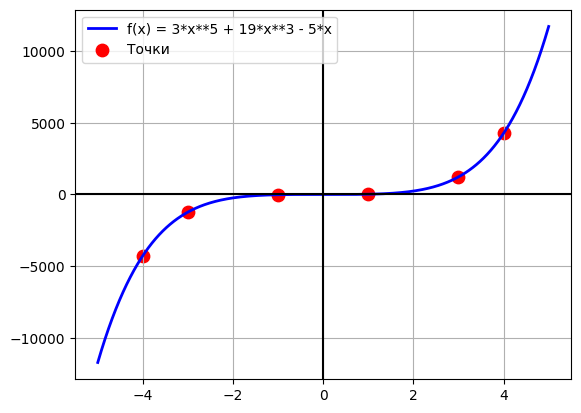

In [92]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

x = sp.Symbol('x')
f = 3*x**5 + 19*x**3 - 5*x

# Численная функция
f_num = sp.lambdify(x, f, 'numpy')

# Диапазон
x_vals = np.linspace(-5, 5, 500)
y_vals = f_num(x_vals)

# Точки
points_x = [-4, -3, -1, 1, 3, 4]
points_y = [-4268, -1227, -17, 17, 1227, 4268]

# График 
plt.plot(x_vals, y_vals, 'b-', lw=2, label=f'f(x) = {f}')
plt.scatter(points_x, points_y, c='r', s=80, label='Точки')
plt.axhline(0, color='k')
plt.axvline(0, color='k')
plt.grid(True)
plt.legend()
plt.show()

Полином: f(x) = x*(3*x**4 + 19*x**2 - 5)
Функция нечётная
Действительные нули: [0, -sqrt(-19/6 + sqrt(421)/6), sqrt(-19/6 + sqrt(421)/6)]
Численно: [0.0, -0.5030381908435964, 0.5030381908435964]
f(x) > 0: ((x < oo) & (sqrt(-19/6 + sqrt(421)/6) < x)) | ((x < 0) & (-sqrt(-19/6 + sqrt(421)/6) < x))
f(x) < 0: ((0 < x) & (x < sqrt(-19/6 + sqrt(421)/6))) | ((-oo < x) & (x < -sqrt(-19/6 + sqrt(421)/6)))


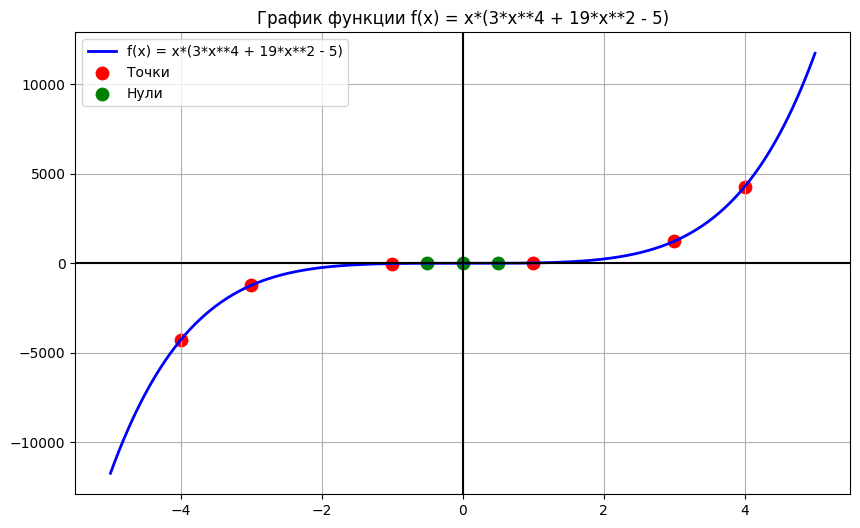

In [93]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

x = sp.Symbol('x')

# Точки
points = [(-4, -4268), (-3, -1227), (-1, -17), (1, 17), (3, 1227), (4, 4268)]

# Коэффициенты полинома 5-й степени
a5, a4, a3, a2, a1, a0 = sp.symbols('a5 a4 a3 a2 a1 a0')

# Составляем уравнения
equations = []
for x_val, y_val in points:
    eq = a5*x_val**5 + a4*x_val**4 + a3*x_val**3 + a2*x_val**2 + a1*x_val + a0 - y_val
    equations.append(eq)

# Решаем систему
solution = sp.solve(equations, (a5, a4, a3, a2, a1, a0))

# Формируем полином
f = (a5*x**5 + a4*x**4 + a3*x**3 + a2*x**2 + a1*x + a0).subs(solution)
f = sp.simplify(f)

print(f"Полином: f(x) = {f}")

# Проверка чётности
f_minus = f.subs(x, -x)
if sp.simplify(f - f_minus) == 0:
    print("Функция чётная")
elif sp.simplify(f + f_minus) == 0:
    print("Функция нечётная")
else:
    print("Функция ни чётная, ни нечётная")

# Нули функции
zeros = sp.solve(f, x)
real_zeros = [z for z in zeros if z.is_real]
print(f"Действительные нули: {real_zeros}")
if real_zeros:
    print(f"Численно: {[float(z.evalf()) for z in real_zeros]}")

# Промежутки знакопостоянства
try:
    print(f"f(x) > 0: {sp.solve_univariate_inequality(f > 0, x)}")
except:
    print("f(x) > 0: не удалось определить")
try:
    print(f"f(x) < 0: {sp.solve_univariate_inequality(f < 0, x)}")
except:
    print("f(x) < 0: не удалось определить")

# График
f_num = sp.lambdify(x, f, 'numpy')
x_plot = np.linspace(-5, 5, 500)
y_plot = f_num(x_plot)

plt.figure(figsize=(10, 6))
plt.plot(x_plot, y_plot, 'b-', lw=2, label=f'f(x) = {f}')
plt.scatter([p[0] for p in points], [p[1] for p in points], c='r', s=80, label='Точки')
for z in real_zeros:
    plt.scatter(float(z.evalf()), 0, c='g', s=80, marker='o', label='Нули' if z == real_zeros[0] else '')
plt.axhline(0, color='k')
plt.axvline(0, color='k')
plt.grid(True)
plt.legend()
plt.title(f'График функции f(x) = {f}')
plt.show()

2. 
(−4,−16729), (−3,−3999), (−1,5), (1,1), (3,4005), (4,16735)

In [94]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

def find_polynomial(points):
    """
    Находит полином по заданным точкам.
    
    points: список кортежей (x, y)
    возвращает: символьное выражение полинома
    """
    n = len(points)
    x = sp.Symbol('x')
    coeffs = sp.symbols(f'a0:{n}')
    
    # Строим полином
    f = sum(coeffs[i] * x**i for i in range(n))
    
    # Составляем и решаем систему
    equations = [f.subs(x, x_val) - y_val for x_val, y_val in points]
    solution = sp.solve(equations, coeffs)
    
    if not solution:
        raise ValueError("Система не имеет решения!")
    
    return sp.simplify(f.subs(solution))

def analyze_function(f, x, x_range=None, points=None):
    """
    Исследует функцию: чётность, нули, знакопостоянство.
    
    f: символьное выражение функции
    x: символьная переменная
    x_range: кортеж (x_min, x_max) для графика
    points: точки для отображения на графике
    """
    print("=" * 60)
    print(f"Функция: f(x) = {f}")
    print("=" * 60)
    
    # Чётность
    f_minus = f.subs(x, -x)
    if sp.simplify(f - f_minus) == 0:
        print("Чётность: ЧЁТНАЯ")
    elif sp.simplify(f + f_minus) == 0:
        print("Чётность: НЕЧЁТНАЯ")
    else:
        print("Чётность: НИ ЧЁТНАЯ, НИ НЕЧЁТНАЯ")
    
    # Нули (только действительные)
    all_zeros = sp.solve(f, x)
    real_zeros = [z for z in all_zeros if z.is_real]
    print(f"Нули (действительные): {real_zeros}")
    if real_zeros:
        print(f"Численно: {[float(z.evalf()) for z in real_zeros]}")
    
    # Знакопостоянство
    print("\n--- ПРОМЕЖУТКИ ЗНАКОПОСТОЯНСТВА ---")
    try:
        positive = sp.solve_univariate_inequality(f > 0, x)
        print(f"f(x) > 0: {positive}")
    except Exception as e:
        print(f"f(x) > 0: не удалось определить аналитически ({e})")
    
    try:
        negative = sp.solve_univariate_inequality(f < 0, x)
        print(f"f(x) < 0: {negative}")
    except Exception as e:
        print(f"f(x) < 0: не удалось определить аналитически ({e})")
    
    # Возрастание/убывание
    print("\n--- МОНОТОННОСТЬ ---")
    f_prime = sp.diff(f, x)
    print(f"Производная: f'(x) = {f_prime}")
    
    try:
        increasing = sp.solve_univariate_inequality(f_prime > 0, x)
        print(f"Возрастает: {increasing}")
    except:
        print("Возрастает: не удалось определить")
    
    try:
        decreasing = sp.solve_univariate_inequality(f_prime < 0, x)
        print(f"Убывает: {decreasing}")
    except:
        print("Убывает: не удалось определить")
    
    # ============================================
    # ПОСТРОЕНИЕ ГРАФИКА (исправленная версия)
    # ============================================
    print("\n--- ПОСТРОЕНИЕ ГРАФИКА ---")
    
    # Определяем диапазон для графика
    if x_range is not None:
        x_min, x_max = x_range
    else:
        # Автоматический расчёт диапазона
        x_vals_from_points = [p[0] for p in points] if points else []
        
        if real_zeros:
            x_zeros = [float(z.evalf()) for z in real_zeros]
            x_vals_from_zeros = x_zeros
        else:
            x_vals_from_zeros = []
        
        all_x = x_vals_from_points + x_vals_from_zeros
        if all_x:
            x_min = min(all_x) - 1
            x_max = max(all_x) + 1
        else:
            x_min, x_max = -5, 5
    
    print(f"Диапазон x: [{x_min:.2f}, {x_max:.2f}]")    
    
    # Создаём числовую функцию
    f_numeric = sp.lambdify(x, f, 'numpy')
    
    # Создаём массив x с достаточным количеством точек
    x_vals = np.linspace(x_min, x_max, 2000)    
    
    # Вычисляем y, обрабатывая возможные ошибки (деление на ноль и т.д.)
    y_vals = []
    for xv in x_vals:
        try:
            yv = float(f_numeric(xv))
            # Проверяем, не слишком ли большое значение
            if abs(yv) > 1e6:
                yv = np.nan
            y_vals.append(yv)
        except:
            y_vals.append(np.nan)
    
    y_vals = np.array(y_vals)
    
    # Создаём график
    plt.figure(figsize=(12, 7))
    
    # График функции
    plt.plot(x_vals, y_vals, 'b-', linewidth=2, label=f'f(x) = {f}')
    
    # Исходные точки
    if points:
        x_pts = [p[0] for p in points]
        y_pts = [p[1] for p in points]
        plt.scatter(x_pts, y_pts, c='red', s=100, zorder=5, label='Исходные точки')
        
        # Подписи точек
        for xp, yp in zip(x_pts, y_pts):
            plt.annotate(f'({xp}, {yp})', xy=(xp, yp), xytext=(xp + 0.2, yp + 0.5),
                        fontsize=8, ha='left')
    
    # Нули функции
    for zero in real_zeros:
        z = float(zero.evalf())
        if x_min <= z <= x_max:
            plt.scatter(z, 0, c='green', s=100, zorder=5, marker='o', 
                       edgecolors='darkgreen', linewidth=1.5,
                       label=f'Нуль: x={z:.3f}' if zero == real_zeros[0] else "")
            plt.annotate(f'x={z:.3f}', xy=(z, 0), xytext=(z, -0.5),
                        fontsize=9, ha='center', va='top')
    
    # Оси координат
    plt.axhline(0, color='black', linewidth=0.8)
    plt.axvline(0, color='black', linewidth=0.8)
    
    # Сетка
    plt.grid(True, linestyle='--', alpha=0.6)
    
    # Подписи
    plt.xlabel('x', fontsize=12)
    plt.ylabel('f(x)', fontsize=12)
    plt.title(f'График функции f(x) = {f}', fontsize=14)
    plt.legend(loc='best', fontsize=9)
    
    # Автоматическая настройка пределов y
    valid_y = y_vals[np.isfinite(y_vals)]
    if len(valid_y) > 0:
        y_min, y_max = np.percentile(valid_y, [1, 99])
        y_range = max(abs(y_min), abs(y_max))
        if y_range > 0 and y_range != float('inf'):
            plt.ylim(-y_range * 1.1, y_range * 1.1)
    
    plt.tight_layout()
    plt.show()
    
    return real_zeros





ПРИМЕР 1: Исходные точки
Функция: f(x) = 16*x**5 + 7*x**3 - 25*x + 3
Чётность: НИ ЧЁТНАЯ, НИ НЕЧЁТНАЯ
Нули (действительные): [CRootOf(16*x**5 + 7*x**3 - 25*x + 3, 0), CRootOf(16*x**5 + 7*x**3 - 25*x + 3, 1), CRootOf(16*x**5 + 7*x**3 - 25*x + 3, 2)]
Численно: [-1.0574892005858587, 0.12050625353328547, 0.9864075817324831]

--- ПРОМЕЖУТКИ ЗНАКОПОСТОЯНСТВА ---
f(x) > 0: ((x < oo) & (CRootOf(16*x**5 + 7*x**3 - 25*x + 3, 2) < x)) | ((x < CRootOf(16*x**5 + 7*x**3 - 25*x + 3, 1)) & (CRootOf(16*x**5 + 7*x**3 - 25*x + 3, 0) < x))
f(x) < 0: ((-oo < x) & (x < CRootOf(16*x**5 + 7*x**3 - 25*x + 3, 0))) | ((x < CRootOf(16*x**5 + 7*x**3 - 25*x + 3, 2)) & (CRootOf(16*x**5 + 7*x**3 - 25*x + 3, 1) < x))

--- МОНОТОННОСТЬ ---
Производная: f'(x) = 80*x**4 + 21*x**2 - 25
Возрастает: ((x < oo) & (sqrt(-21/160 + sqrt(8441)/160) < x)) | ((-oo < x) & (x < -sqrt(-21/160 + sqrt(8441)/160)))
Убывает: (x < sqrt(-21/160 + sqrt(8441)/160)) & (-sqrt(-21/160 + sqrt(8441)/160) < x)

--- ПОСТРОЕНИЕ ГРАФИКА ---
Диапазо

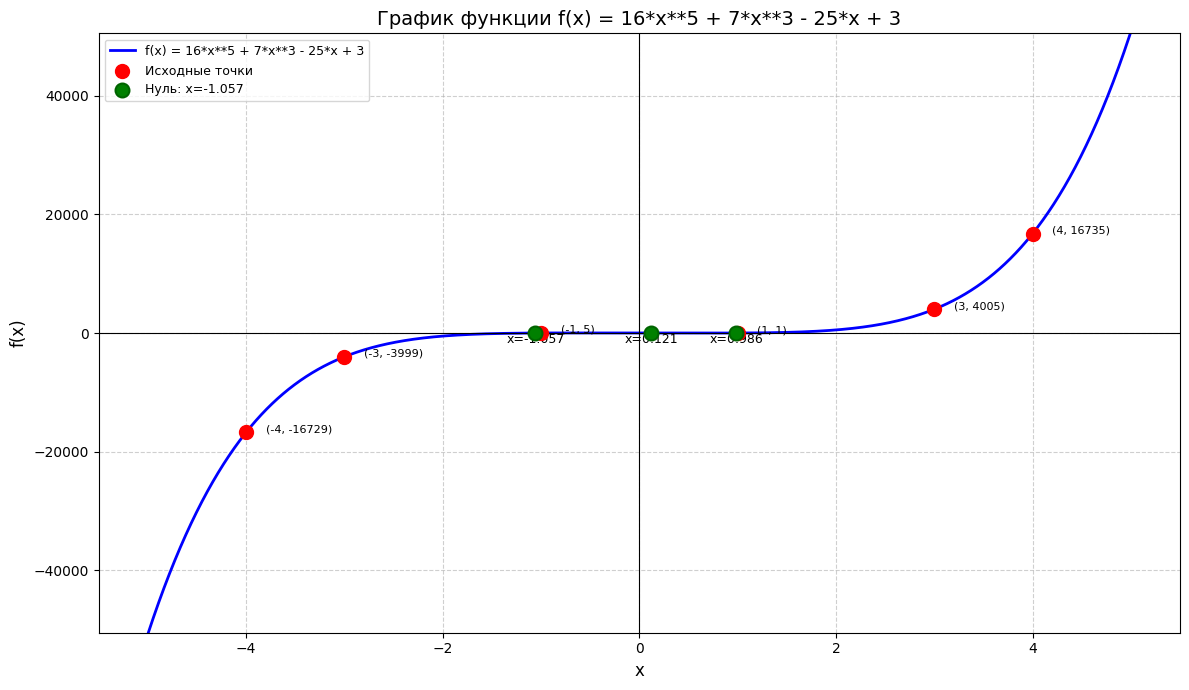

In [95]:
# ============================================
# ПРИМЕРЫ ИСПОЛЬЗОВАНИЯ
# ============================================
x = sp.Symbol('x')

# ПРИМЕР 1: Исходные точки (нечётная функция)
print("\n" * 2)
print("=" * 60)
print("ПРИМЕР 1: Исходные точки")
print("=" * 60)
points1 = [(-4,-16729), (-3,-3999), (-1,5), (1,1), (3,4005), (4,16735)]
f1 = find_polynomial(points1)
analyze_function(f1, x, points=points1)

3. 
(−3,−27), (−2,−8), (−1,−1), (0,0), (1,1), (2,8), (3,27)




ПРИМЕР 1: Исходные точки
Функция: f(x) = x**3
Чётность: НЕЧЁТНАЯ
Нули (действительные): [0]
Численно: [0.0]

--- ПРОМЕЖУТКИ ЗНАКОПОСТОЯНСТВА ---
f(x) > 0: (0 < x) & (x < oo)
f(x) < 0: (-oo < x) & (x < 0)

--- МОНОТОННОСТЬ ---
Производная: f'(x) = 3*x**2
Возрастает: (x > -oo) & (x < oo) & Ne(x, 0)
Убывает: False

--- ПОСТРОЕНИЕ ГРАФИКА ---
Диапазон x: [-4.00, 4.00]


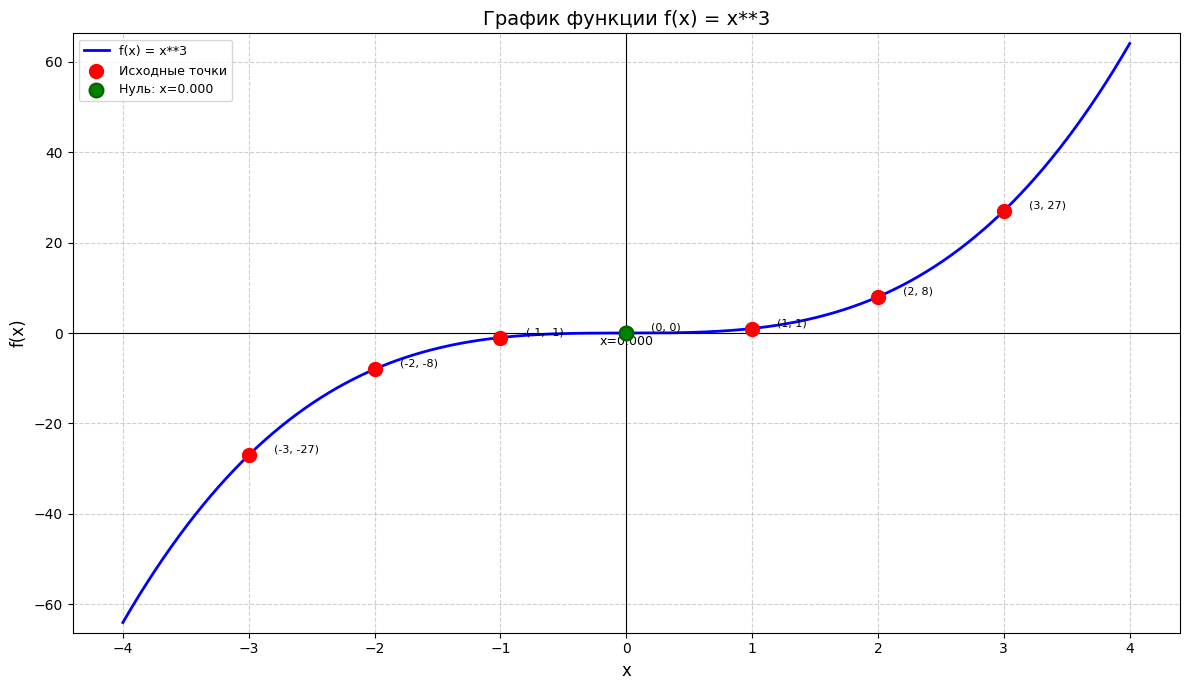

In [96]:
# ============================================
# ПРИМЕРЫ ИСПОЛЬЗОВАНИЯ
# ============================================
x = sp.Symbol('x')

# ПРИМЕР 1: Исходные точки (нечётная функция)
print("\n" * 2)
print("=" * 60)
print("ПРИМЕР 1: Исходные точки")
print("=" * 60)
points1 = [(-3,-27), (-2,-8), (-1,-1), (0,0), (1,1), (2,8), (3,27)]
f1 = find_polynomial(points1)
analyze_function(f1, x, points=points1)

4. 
(−3,9), (−2,4), (−1,1), (0,0), (1,1), (2,4), (3,9)




ПРИМЕР 1: Исходные точки
Функция: f(x) = x**2
Чётность: ЧЁТНАЯ
Нули (действительные): [0]
Численно: [0.0]

--- ПРОМЕЖУТКИ ЗНАКОПОСТОЯНСТВА ---
f(x) > 0: (x > -oo) & (x < oo) & Ne(x, 0)
f(x) < 0: False

--- МОНОТОННОСТЬ ---
Производная: f'(x) = 2*x
Возрастает: (0 < x) & (x < oo)
Убывает: (-oo < x) & (x < 0)

--- ПОСТРОЕНИЕ ГРАФИКА ---
Диапазон x: [-4.00, 4.00]


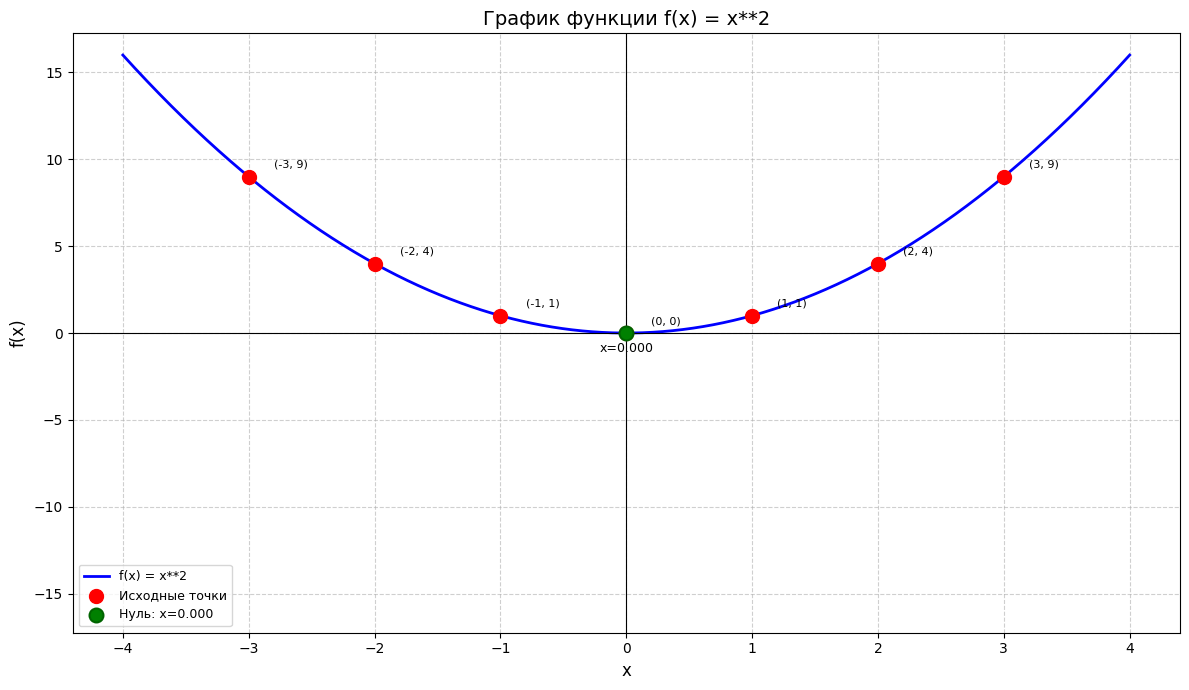

In [97]:
# ============================================
# ПРИМЕРЫ ИСПОЛЬЗОВАНИЯ
# ============================================
x = sp.Symbol('x')

# ПРИМЕР 1: Исходные точки (нечётная функция)
print("\n" * 2)
print("=" * 60)
print("ПРИМЕР 1: Исходные точки")
print("=" * 60)
points1 = [(-3,9), (-2,4), (-1,1), (0,0), (1,1), (2,4), (3,9)]
f1 = find_polynomial(points1)
analyze_function(f1, x, points=points1)

5. 
(−2,−8), (−1,−1), (0,0), (1,1), (2,8)




ПРИМЕР 1: Исходные точки
Функция: f(x) = x**3
Чётность: НЕЧЁТНАЯ
Нули (действительные): [0]
Численно: [0.0]

--- ПРОМЕЖУТКИ ЗНАКОПОСТОЯНСТВА ---
f(x) > 0: (0 < x) & (x < oo)
f(x) < 0: (-oo < x) & (x < 0)

--- МОНОТОННОСТЬ ---
Производная: f'(x) = 3*x**2
Возрастает: (x > -oo) & (x < oo) & Ne(x, 0)
Убывает: False

--- ПОСТРОЕНИЕ ГРАФИКА ---
Диапазон x: [-3.00, 3.00]


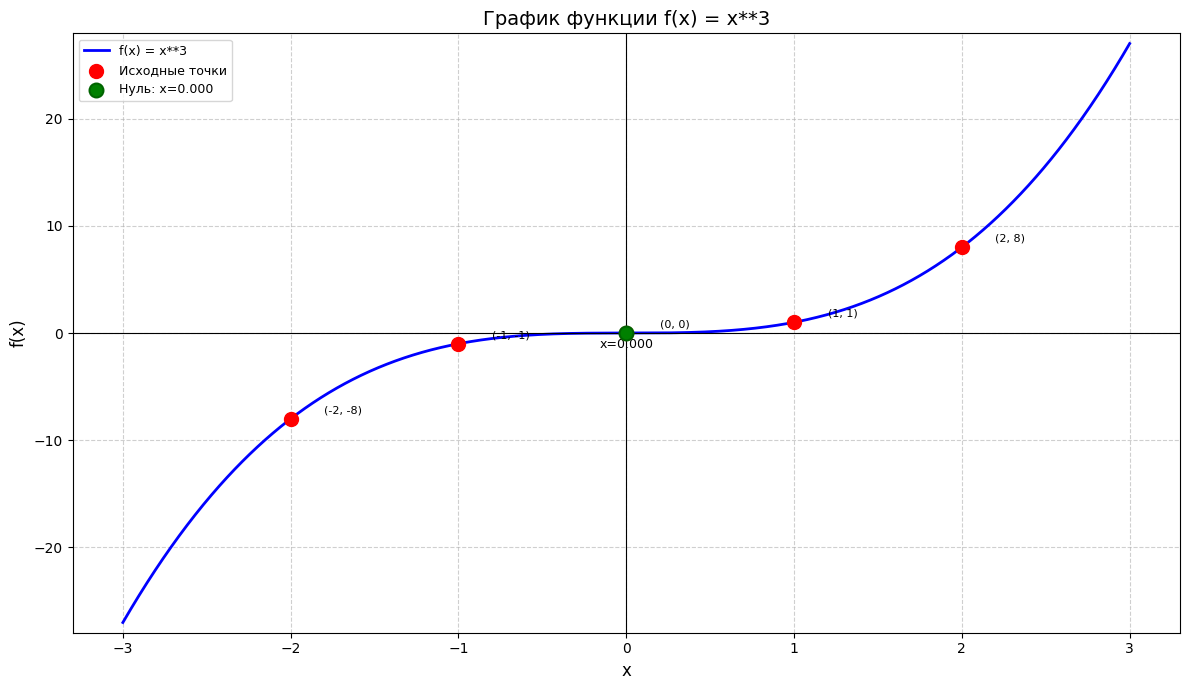

In [98]:
# ============================================
# ПРИМЕРЫ ИСПОЛЬЗОВАНИЯ
# ============================================
x = sp.Symbol('x')

# ПРИМЕР 1: Исходные точки (нечётная функция)
print("\n" * 2)
print("=" * 60)
print("ПРИМЕР 1: Исходные точки")
print("=" * 60)
points1 = [(-2,-8), (-1,-1), (0,0), (1,1), (2,8)]
f1 = find_polynomial(points1)
analyze_function(f1, x, points=points1)

6. 
(−2,4), (−1,1), (0,0), (1,−1), (2,−4)




ПРИМЕР 1: Исходные точки
Функция: f(x) = x*(-x**2 - 2)/3
Чётность: НЕЧЁТНАЯ
Нули (действительные): [0]
Численно: [0.0]

--- ПРОМЕЖУТКИ ЗНАКОПОСТОЯНСТВА ---
f(x) > 0: (-oo < x) & (x < 0)
f(x) < 0: (0 < x) & (x < oo)

--- МОНОТОННОСТЬ ---
Производная: f'(x) = -x**2 - 2/3
Возрастает: False
Убывает: (-oo < x) & (x < oo)

--- ПОСТРОЕНИЕ ГРАФИКА ---
Диапазон x: [-3.00, 3.00]


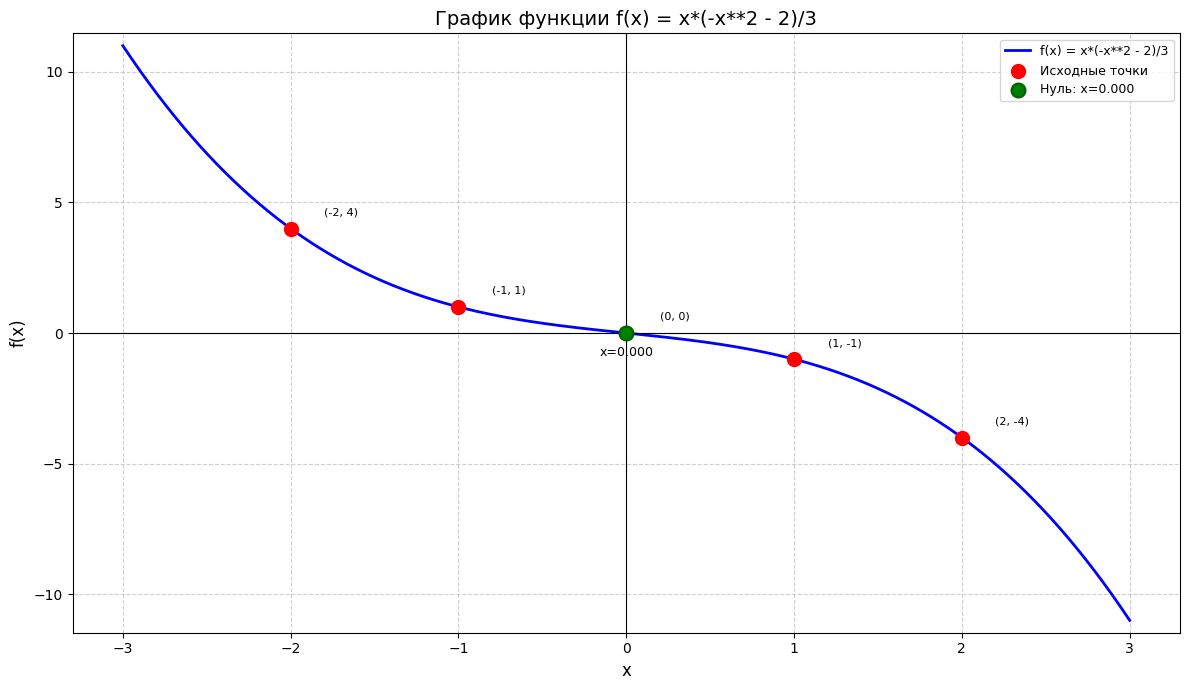

In [99]:
# ============================================
# ПРИМЕРЫ ИСПОЛЬЗОВАНИЯ
# ============================================
x = sp.Symbol('x')

# ПРИМЕР 1: Исходные точки (нечётная функция)
print("\n" * 2)
print("=" * 60)
print("ПРИМЕР 1: Исходные точки")
print("=" * 60)
points1 = [(-2,4), (-1,1), (0,0), (1,-1), (2,-4)]
f1 = find_polynomial(points1)
analyze_function(f1, x, points=points1)

### Блок 2. Преобразование графиков

Минимизируйте среднеквадратичную ошибку, используя изученные в курсе преобразования функций (сдвиг, растяжение/сжатие, отражение).

Для каждого задания дан набор точек и исходная функция.
Примените к функции преобразования 
$x -> \frac{x+a}{b}$

​
или последовательные сдвиги/масштабирования, чтобы MSE стал меньше заданного порога.

#### Задание 2.1 (MSE < 5)

Точки:

$X=[−2,−1,0,1,2,3,3.5,4,4.5,5]$

$Y=[2,−4,1,8,21,40,47,65,75,92]$

Исходная функция:

$f(x) = 48x^2 - 128x + 83$

MSE = 4.4125


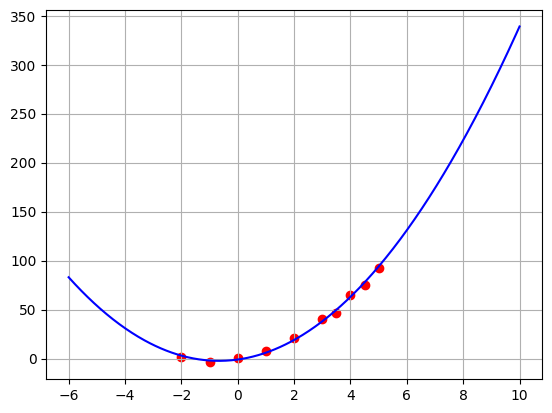

In [100]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

x = sp.Symbol('x')

# Точки
X = np.array([-2, -1, 0, 1, 2, 3, 3.5, 4, 4.5, 5])
Y = np.array([2, -4, 1, 8, 21, 40, 47, 65, 75, 92])

# Исходная функция
f = 48 * x**2 - 128 * x + 83

# Преобразование (подобранное)
a, b = 6, 4
f_new = f.subs(x, (x + a) / b)

# MSE
f_num = sp.lambdify(x, f_new, 'numpy')
y_pred = f_num(X)
mse = np.mean((Y - y_pred)**2)
print(f"MSE = {mse:.4f}")

# График
plt.scatter(X, Y, c='r')
x_plot = np.linspace(-6, 10, 500)
plt.plot(x_plot, f_num(x_plot), 'b')
plt.grid()
plt.show()

In [101]:
f1 = 48 * x**2 - 128 * x + 83
f1

In [102]:
# Сместим график на шесть единиц влево:
# Растянем график вдоль оси Ox, поделив аргумент на четыре
f1_1 = f1.subs(x, (x + 6) / 4)
print_points_ands_function_my(f1_1)
expand(f1_1)

NameError: name 'print_points_ands_function_my' is not defined

MSE исходной: 93691.3000
MSE преобразованной: 4.4125


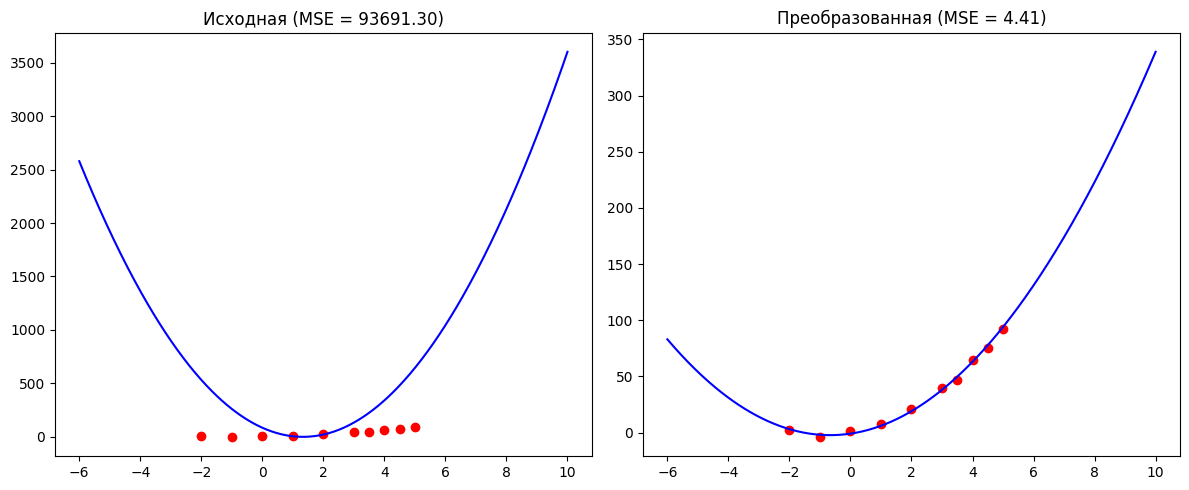

In [103]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

x = sp.Symbol('x')

# Данные (можно менять под свою задачу)
X = np.array([-2, -1, 0, 1, 2, 3, 3.5, 4, 4.5, 5])
Y = np.array([2, -4, 1, 8, 21, 40, 47, 65, 75, 92])
f = 48 * x**2 - 128 * x + 83

# Преобразование (подберите a и b)
a, b = 6, 4
f_new = f.subs(x, (x + a) / b)

# Расчёт MSE
f_num = sp.lambdify(x, f, 'numpy')
f_new_num = sp.lambdify(x, f_new, 'numpy')

mse_old = np.mean((Y - f_num(X))**2)
mse_new = np.mean((Y - f_new_num(X))**2)

print(f"MSE исходной: {mse_old:.4f}")
print(f"MSE преобразованной: {mse_new:.4f}")

# Графики
x_plot = np.linspace(-6, 10, 500)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X, Y, c='r')
plt.plot(x_plot, f_num(x_plot), 'b')
plt.title(f'Исходная (MSE = {mse_old:.2f})')

plt.subplot(1, 2, 2)
plt.scatter(X, Y, c='r')
plt.plot(x_plot, f_new_num(x_plot), 'b')
plt.title(f'Преобразованная (MSE = {mse_new:.2f})')

plt.tight_layout()
plt.show()

#### Задание 2.2 (MSE < 35)

Точки:

$X=[−2,−1,0,1,2,3,3.5,4,4.5,5]$

$Y=[−31,−9,4,−1,9,24,47,92,120,170]$

Исходная функция:

$f(x) = 4x^3 + 30x^2 + 74x + 62$

In [104]:
def print_points_ands_function2(sympy_function):
    def function(x_): return float(sympy_function.subs(x, x_))
    
    points_X = np.array([-2, -1, 0, 1, 2, 3, 3.5, 4, 4.5, 5])
    points_Y = np.array([-31, -9, 4, -1, 9, 24, 47, 92, 120, 170])
    plt.xlim(-3, 6)
    plt.ylim(-35, 200)
    
    plt.scatter(points_X, points_Y, c='r')
    x_range = np.linspace(plt.xlim()[0], plt.xlim()[1], num=100)
    function_Y = [function(x_) for x_ in x_range]
    plt.plot(x_range, function_Y, 'b')
    plt.show()
    
    MSE = sum([(points_Y[i] - function(points_X[i]))**2 for i in range(len(points_Y))]) / len(points_Y)
    print(f'MSE = {MSE}')


In [105]:
f2 = 4 * x**3 + 30 * x**2 + 74 * x + 62
f2

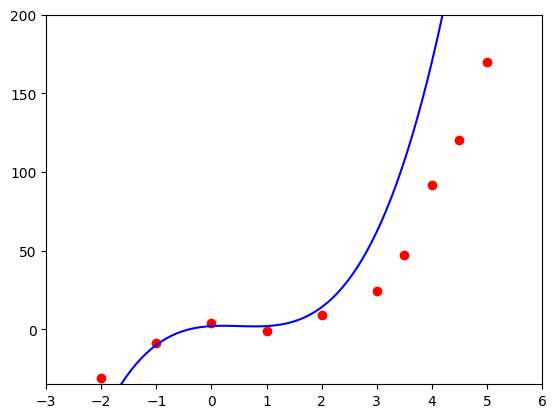

MSE = 6671.6
4*x**3 - 6*x**2 + 2*x + 2


In [106]:
# Сместим график на три единицы вправо:
f2_1 = f2.subs(x, x - 3)
print_points_ands_function2(f2_1)
print(expand(f2_1))

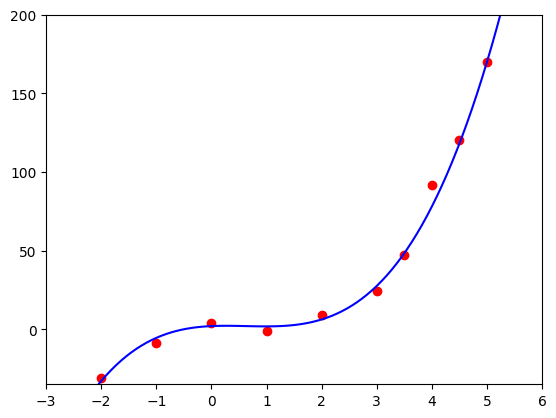

MSE = 24.89321599999999


In [107]:
# Растянем график вдоль оси Ox:
f2_2 = f2_1.subs(x, x * 0.8)
print_points_ands_function2(f2_2)
expand(f2_2)

ЗАДАНИЕ 2.2 (MSE < 35)
Исходная функция: f(x) = 4*x**3 + 30*x**2 + 74*x + 62
Преобразования: сдвиг вправо на 3, затем x → 0.8·x
Преобразованная функция: f(x) = 2.048*x**3 - 3.84*x**2 + 1.59999999999999*x + 2

MSE исходной функции = 607200.20
MSE преобразованной функции = 24.89
MSE < 35: True


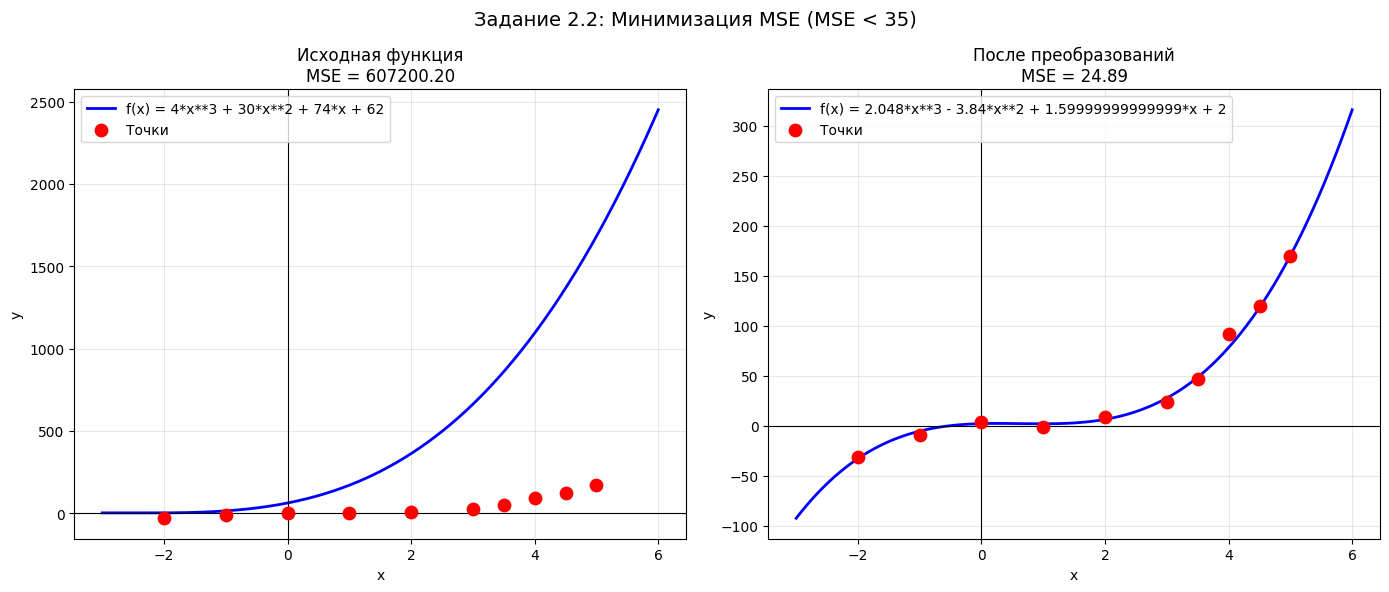

In [108]:
import sympy as sp
import numpy as np
import matplotlib.pyplot as plt

x = sp.Symbol('x')

# ============================================
# ДАННЫЕ
# ============================================
X = np.array([-2, -1, 0, 1, 2, 3, 3.5, 4, 4.5, 5])
Y = np.array([-31, -9, 4, -1, 9, 24, 47, 92, 120, 170])

# Исходная функция
f_original = 4 * x**3 + 30 * x**2 + 74 * x + 62

# ============================================
# ПРЕОБРАЗОВАНИЯ (последовательные)
# ============================================
# Шаг 1: сдвиг вправо на 3
f_shifted = f_original.subs(x, x - 3)

# Шаг 2: растяжение (умножение аргумента на 0.8)
f_transformed = f_shifted.subs(x, x * 0.8)

# Упрощаем
f_transformed_simple = sp.expand(f_transformed)

print("=" * 60)
print("ЗАДАНИЕ 2.2 (MSE < 35)")
print("=" * 60)
print(f"Исходная функция: f(x) = {f_original}")
print(f"Преобразования: сдвиг вправо на 3, затем x → 0.8·x")
print(f"Преобразованная функция: f(x) = {f_transformed_simple}")

# ============================================
# ВЫЧИСЛЕНИЕ MSE
# ============================================
f_original_num = sp.lambdify(x, f_original, 'numpy')
f_transformed_num = sp.lambdify(x, f_transformed, 'numpy')

y_pred_original = f_original_num(X)
y_pred_transformed = f_transformed_num(X)

mse_original = np.mean((Y - y_pred_original)**2)
mse_transformed = np.mean((Y - y_pred_transformed)**2)

print(f"\nMSE исходной функции = {mse_original:.2f}")
print(f"MSE преобразованной функции = {mse_transformed:.2f}")
print(f"MSE < 35: {mse_transformed < 35}")

# ============================================
# ПОСТРОЕНИЕ ГРАФИКОВ
# ============================================
x_plot = np.linspace(-3, 6, 500)

plt.figure(figsize=(14, 6))

# Исходный график
plt.subplot(1, 2, 1)
plt.plot(x_plot, f_original_num(x_plot), 'b-', lw=2, label=f'f(x) = {f_original}')
plt.scatter(X, Y, c='red', s=80, zorder=5, label='Точки')
plt.axhline(0, color='black', lw=0.8)
plt.axvline(0, color='black', lw=0.8)
plt.grid(True, alpha=0.3)
plt.xlabel('x')
plt.ylabel('y')
plt.title(f'Исходная функция\nMSE = {mse_original:.2f}')
plt.legend()

# Преобразованный график
plt.subplot(1, 2, 2)
plt.plot(x_plot, f_transformed_num(x_plot), 'b-', lw=2, label=f'f(x) = {f_transformed_simple}')
plt.scatter(X, Y, c='red', s=80, zorder=5, label='Точки')
plt.axhline(0, color='black', lw=0.8)
plt.axvline(0, color='black', lw=0.8)
plt.grid(True, alpha=0.3)
plt.xlabel('x')
plt.ylabel('y')
plt.title(f'После преобразований\nMSE = {mse_transformed:.2f}')
plt.legend()

plt.suptitle('Задание 2.2: Минимизация MSE (MSE < 35)', fontsize=14)
plt.tight_layout()
plt.show()

#### Задание 2.3 (MSE < 300)

Точки:

$X=[0,1,2,3,4,5,6,7,8]$

$Y=[10,20,35,55,80,110,145,185,230]$

Исходная функция:

$f(x) = 1.5x^2 + 3.5x + 8$

In [109]:
def print_points_ands_function2_3(sympy_function):
    def function(x_): return float(sympy_function.subs(x, x_))
    
    points_X = np.array([0,1,2,3,4,5,6,7,8])
    points_Y = np.array([10,20,35,55,80,110,145,185,230])
    plt.xlim(-10, 20)
    plt.ylim(-5, 100)
    
    plt.scatter(points_X, points_Y, c='r')
    x_range = np.linspace(plt.xlim()[0], plt.xlim()[1], num=100)
    function_Y = [function(x_) for x_ in x_range]
    plt.plot(x_range, function_Y, 'b')
    plt.show()
    
    MSE = sum([(points_Y[i] - function(points_X[i]))**2 for i in range(len(points_Y))]) / len(points_Y)
    print(f'MSE = {MSE}')

In [110]:
# Исходная функция
f_original = 1.5 * x**2 + 3.5 * x + 8
f_original

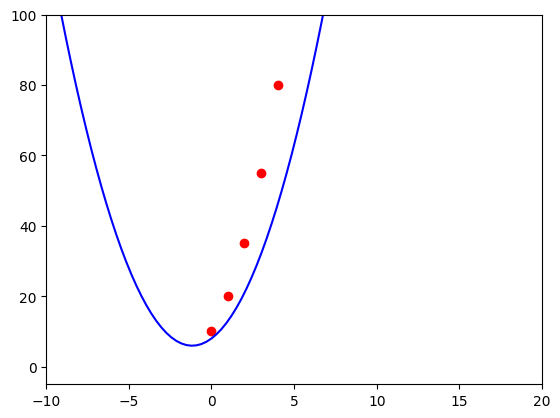

MSE = 2648.0


In [111]:
print_points_ands_function2_3(f_original)

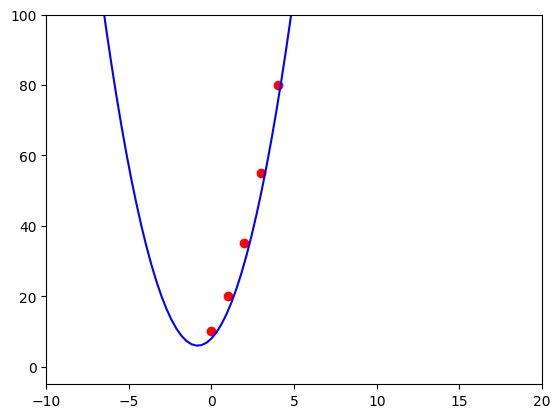

MSE = 18.156799999999983


In [112]:
f_new_1 = f_original.subs(x, x * 1.4)
print_points_ands_function2_3(f_new_1)
expand(f_new_1)

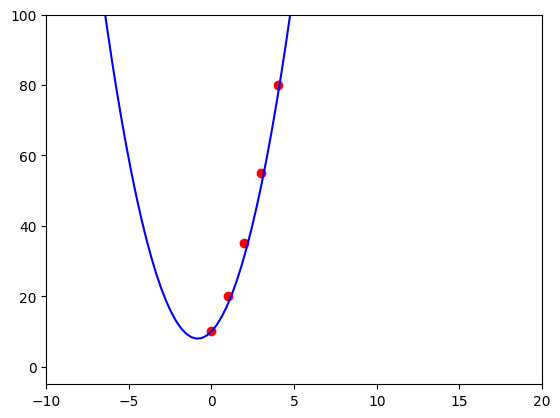

MSE = 12.450133333333254


In [113]:
f_new_2 = f_new_1+2
print_points_ands_function2_3(f_new_2)
expand(f_new_2)

#### Задание 2.4 (MSE < 25)

Точки:

$X=[0,1,2,3,4,5,6]$

$Y=[2,3,6,11,18,27,38]$

Исходная функция:

$f(x) = x^2 + x + 2$

In [114]:
def print_points_ands_function2_4(sympy_function):
    def function(x_): return float(sympy_function.subs(x, x_))
    
    points_X = np.array([0,1,2,3,4,5,6])
    points_Y = np.array([2,3,6,11,18,27,38])
    plt.xlim(-10, 10)
    plt.ylim(-2, 100)
    
    plt.scatter(points_X, points_Y, c='r')
    x_range = np.linspace(plt.xlim()[0], plt.xlim()[1], num=100)
    function_Y = [function(x_) for x_ in x_range]
    plt.plot(x_range, function_Y, 'b')
    plt.show()
    
    MSE = sum([(points_Y[i] - function(points_X[i]))**2 for i in range(len(points_Y))]) / len(points_Y)
    print(f'MSE = {MSE}')

In [115]:
# Исходная функция
f_2_4 = x**2 + x + 2
f_2_4

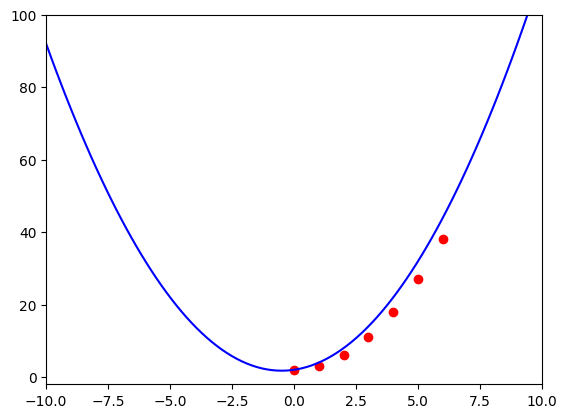

MSE = 13.0


In [116]:
print_points_ands_function2_4(f_2_4)

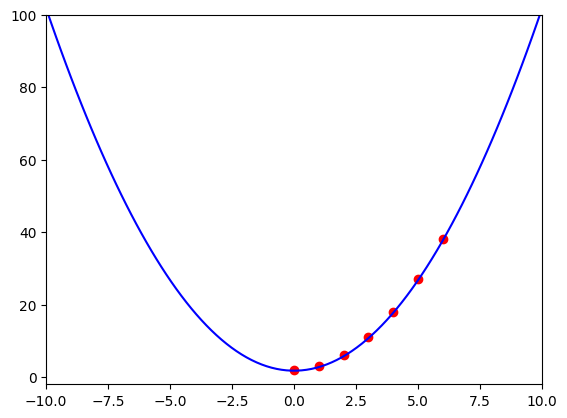

MSE = 0.0625


In [117]:
f_new_1 = f_2_4.subs(x, x - 0.5)
print_points_ands_function2_4(f_new_1)
expand(f_new_1)

#### Задание 2.5 (MSE < 100)

Точки:

$X=[−3,−2,−1,0,1,2,3]$

$Y=[−20,5,14,10,2,−5,−25]$

Исходная функция:

$f(x) = -2x^3 + 4x^2 + 5x - 8$

In [118]:
def print_points_ands_function2_5(sympy_function):
    def function(x_): return float(sympy_function.subs(x, x_))
    
    points_X = np.array([-3,-2,-1,0,1,2,3])
    points_Y = np.array([-20,5,14,10,2,-5,-25])
    plt.xlim(-10, 10)
    plt.ylim(-30, 30)
    
    plt.scatter(points_X, points_Y, c='r')
    x_range = np.linspace(plt.xlim()[0], plt.xlim()[1], num=100)
    function_Y = [function(x_) for x_ in x_range]
    plt.plot(x_range, function_Y, 'b')
    plt.show()
    
    MSE = sum([(points_Y[i] - function(points_X[i]))**2 for i in range(len(points_Y))]) / len(points_Y)
    print(f'MSE = {MSE}')

In [119]:
# Исходная функция
f_2_5 = -2 * x**2 + 4 * x**2 + 5 * x - 8
f_2_5

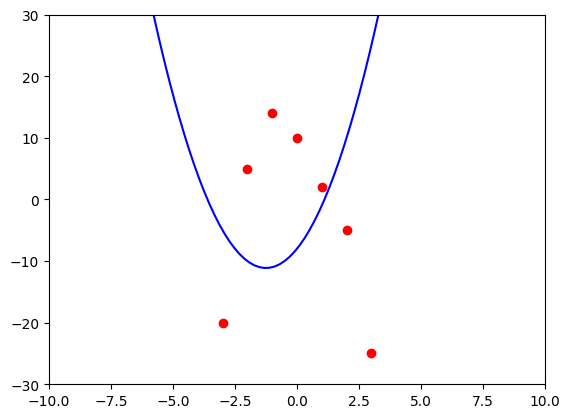

MSE = 590.4285714285714


In [120]:
print_points_ands_function2_5(f_2_5)

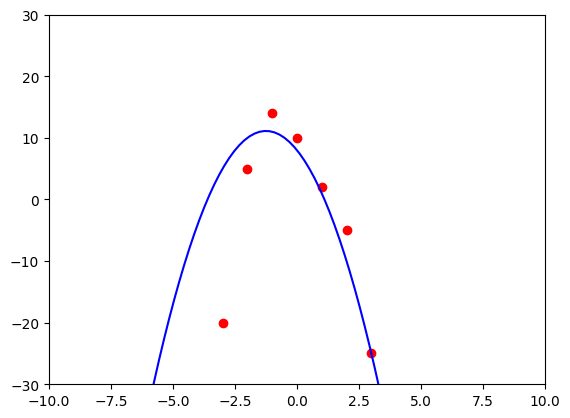

MSE = 98.42857142857143


In [121]:
# Перевернем функцию
f_new_1 = -f_2_5
print_points_ands_function2_5(f_new_1)
expand(f_new_1)

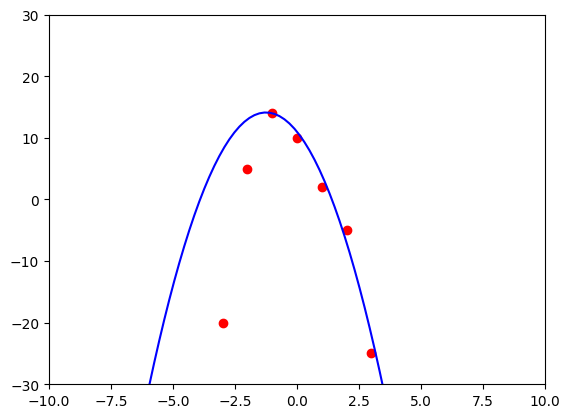

MSE = 123.71428571428571


In [122]:
# Поднимем функцию вдоль y
f_new_2 = f_new_1 + 3
print_points_ands_function2_5(f_new_2)
expand(f_new_2)

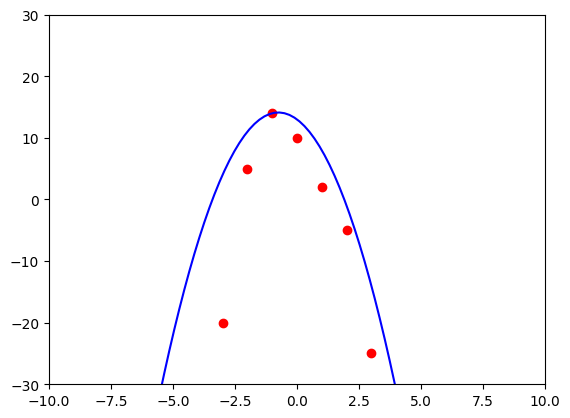

MSE = 113.42857142857143


In [123]:
# Поднимем функцию вдоль y
f_new_3 = f_new_2.subs(x, x - 0.5)
print_points_ands_function2_5(f_new_3)
expand(f_new_3)

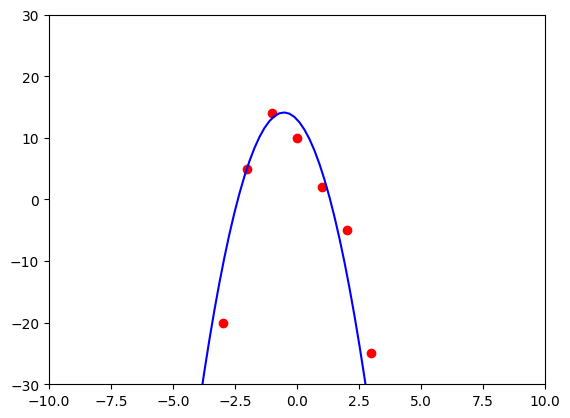

MSE = 40.25655976676387


In [124]:
# Поднимем функцию вдоль y
f_new_4 = f_new_3.subs(x, x / 0.7)
print_points_ands_function2_5(f_new_4)
expand(f_new_4)

#### Задание 2.6 (MSE < 0.10)

Точки:

$X=[0,1,2,3,4,5,6,7,8,9]$

$Y=[0,0.5,1.0,1.5,2.0,2.5,3.0,3.5,4.0,4.5]$

Исходная функция:

$f(x) = 0.6x + 0.2$

In [125]:
def print_points_ands_function2_6(sympy_function):
    def function(x_): return float(sympy_function.subs(x, x_))
    
    points_X = np.array([0,1,2,3,4,5,6,7,8,9])
    points_Y = np.array([0,0.5,1.0,1.5,2.0,2.5,3.0,3.5,4.0,4.5])
    plt.xlim(-10, 10)
    plt.ylim(-30, 30)
    
    plt.scatter(points_X, points_Y, c='r')
    x_range = np.linspace(plt.xlim()[0], plt.xlim()[1], num=100)
    function_Y = [function(x_) for x_ in x_range]
    plt.plot(x_range, function_Y, 'b')
    plt.show()
    
    MSE = sum([(points_Y[i] - function(points_X[i]))**2 for i in range(len(points_Y))]) / len(points_Y)
    print(f'MSE = {MSE}')

In [126]:
# Исходная функция
f_2_6 = 0.6 * x + 0.2
f_2_6

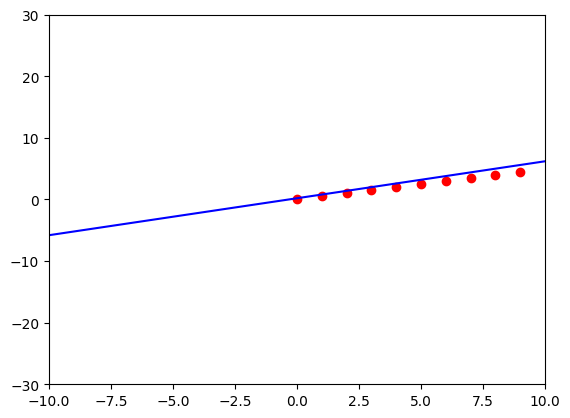

MSE = 0.505


In [127]:
print_points_ands_function2_6(f_2_6)

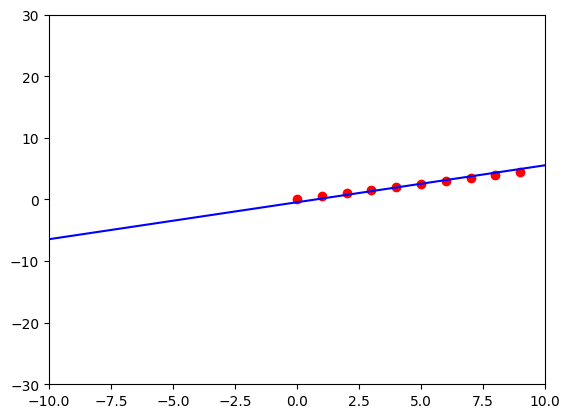

MSE = 0.0824999999999999


In [128]:
# Поднимем функцию вдоль y
f_new_1 = f_2_6-0.65
print_points_ands_function2_6(f_new_1)
expand(f_new_1)